In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks', 'electricity.txt']

In [5]:
file_path = '/content/drive/MyDrive/electricity.txt'

In [6]:
import os

os.path.exists(file_path)

True

In [7]:
import pandas as pd

df = pd.read_csv(file_path)

In [8]:
df.head()

,timestamp,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


In [9]:
df.shape

(17544, 1579)

In [10]:
list(df.columns[:10])

['timestamp',
 'Panther_parking_Lorriane',
 'Panther_lodging_Cora',
 'Panther_office_Hannah',
 'Panther_lodging_Hattie',
 'Panther_education_Teofila',
 'Panther_education_Jerome',
 'Panther_retail_Felix',
 'Panther_parking_Asia',
 'Panther_education_Misty']

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Columns: 1579 entries, timestamp to Mouse_science_Micheal
dtypes: float64(1578), object(1)
memory usage: 211.3+ MB


In [12]:
df.isnull().sum().sum()

np.int64(1312095)

In [13]:
missing_values = df.isnull().sum()

missing_values.sort_values(ascending=False).head(10)

,0
Eagle_lodging_Garland,17544
Rat_public_Ulysses,17544
Bobcat_education_Barbra,17434
Bobcat_education_Seth,16885
Rat_education_Mac,16631
Rat_education_Angelica,16031
Rat_education_Kristie,15983
Rat_education_Chance,15767
Peacock_public_Linda,14666
Bobcat_public_Angie,14563


In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False).head(10)

,0
Eagle_lodging_Garland,100.000000
Rat_public_Ulysses,100.000000
Bobcat_education_Barbra,99.373005
Bobcat_education_Seth,96.243730
Rat_education_Mac,94.795942
Rat_education_Angelica,91.375969
Rat_education_Kristie,91.102371
Rat_education_Chance,89.871181
Peacock_public_Linda,83.595531
Bobcat_public_Angie,83.008436


In [15]:
total_cells = df.size

total_missing = df.isnull().sum().sum()

overall_missing_percentage = (total_missing / total_cells) * 100

print("Total cells:", total_cells)
print("Total missing values:", total_missing)
print("Overall missing percentage:", overall_missing_percentage)

Total cells: 27701976
Total missing values: 1312095
Overall missing percentage: 4.736467174760385


In [16]:
completely_empty_meters = (df.isnull().sum() == len(df)).sum()

print("Completely empty meters:", completely_empty_meters)

Completely empty meters: 2


In [17]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

top_10_missing = missing_percentage.drop("timestamp").sort_values(
    ascending=False
).head(10)

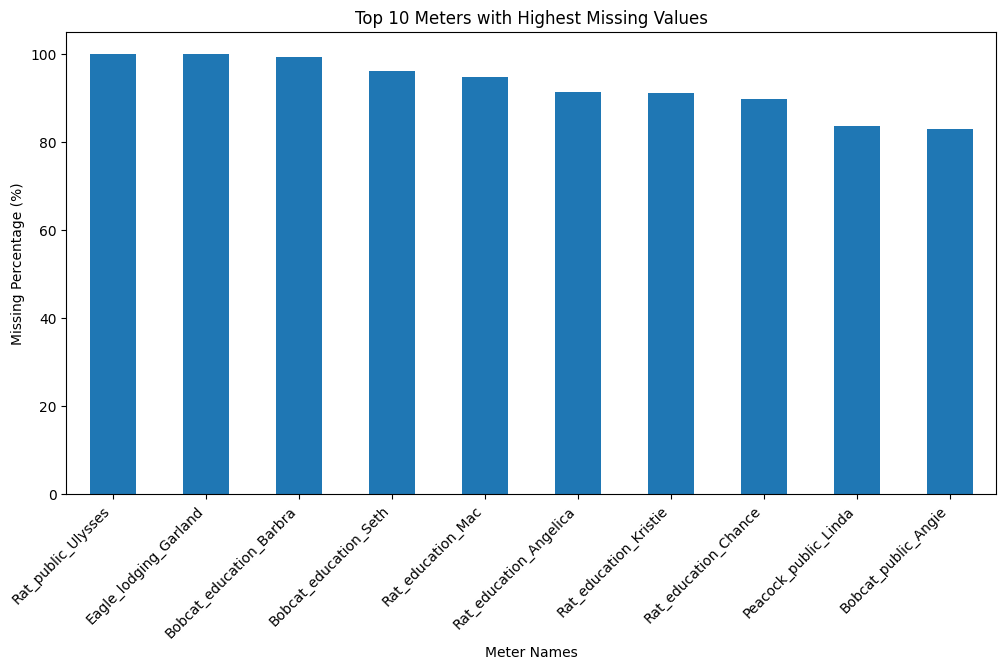

In [18]:
plt.figure(figsize=(12, 6))

top_10_missing.plot(kind="bar")

plt.title("Top 10 Meters with Highest Missing Values")
plt.xlabel("Meter Names")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45, ha="right")

plt.show()

In [19]:
df["timestamp"].dtype

dtype('O')

In [20]:
df["timestamp"].head()

,timestamp
0,2016-01-01 00:00:00
1,2016-01-01 01:00:00
2,2016-01-01 02:00:00
3,2016-01-01 03:00:00
4,2016-01-01 04:00:00


In [21]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [22]:
df["timestamp"].dtype

dtype('<M8[ns]')

In [23]:
df["timestamp"].head()

,timestamp
0,2016-01-01 00:00:00
1,2016-01-01 01:00:00
2,2016-01-01 02:00:00
3,2016-01-01 03:00:00
4,2016-01-01 04:00:00


In [24]:
print("Starting date:", df["timestamp"].min())

print("Ending date:", df["timestamp"].max())

Starting date: 2016-01-01 00:00:00
Ending date: 2017-12-31 23:00:00


In [25]:
df["timestamp"].is_monotonic_increasing

True

In [26]:
df["timestamp"].duplicated().sum()

np.int64(0)

In [27]:
time_difference = df["timestamp"].diff()

time_difference.value_counts()

,count
timestamp,
0 days 01:00:00,17543


In [28]:
missing_intervals = (time_difference / pd.Timedelta(hours=1)) - 1

missing_intervals[missing_intervals > 0].sum()

np.float64(0.0)

In [29]:
meter_name = "Panther_parking_Lorriane"

meter_data = df[["timestamp", meter_name]]

In [30]:
meter_data.head()

,timestamp,Panther_parking_Lorriane
0,2016-01-01 00:00:00,0.0
1,2016-01-01 01:00:00,0.0
2,2016-01-01 02:00:00,0.0
3,2016-01-01 03:00:00,0.0
4,2016-01-01 04:00:00,0.0


In [31]:
meter_data.describe()

,timestamp,Panther_parking_Lorriane
count,17544,17533.000000
mean,2016-12-31 11:30:00,8.661108
min,2016-01-01 00:00:00,0.000000
25%,2016-07-01 17:45:00,6.661300
50%,2016-12-31 11:30:00,9.601900
75%,2017-07-02 05:15:00,12.662500
max,2017-12-31 23:00:00,25.497200
std,NaN,4.900062


In [32]:
meter_data[meter_name].isnull().sum()

np.int64(11)

In [33]:
(meter_data[meter_name] == 0).sum()

np.int64(3371)

In [34]:
zero_percentage = (
    (meter_data[meter_name] == 0).sum()
    / meter_data[meter_name].count()
) * 100

print("Zero reading percentage:", zero_percentage)

Zero reading percentage: 19.226601266183767


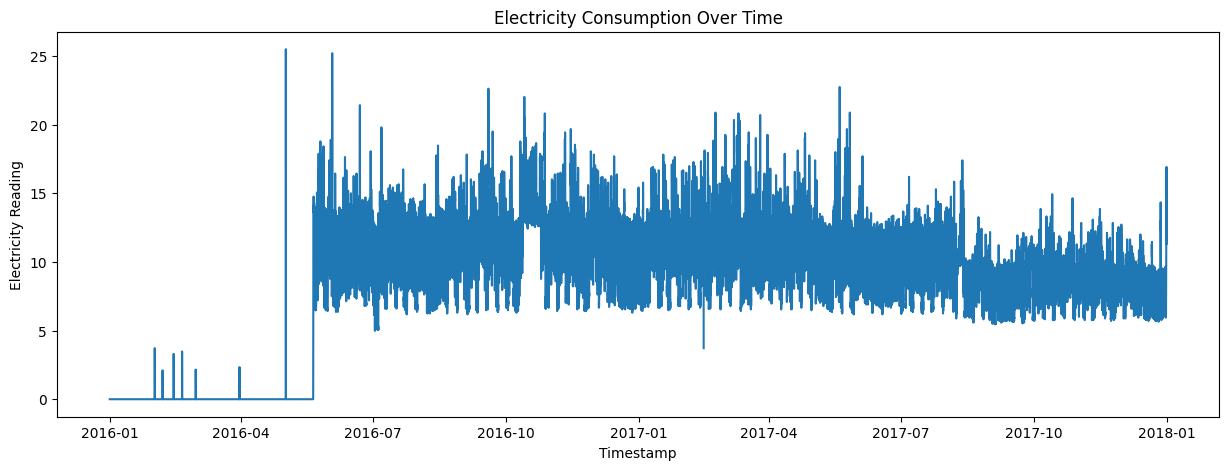

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(meter_data["timestamp"], meter_data[meter_name])

plt.xlabel("Timestamp")
plt.ylabel("Electricity Reading")
plt.title("Electricity Consumption Over Time")

plt.show()

In [36]:
monthly_average = meter_data.set_index("timestamp")[meter_name].resample("ME").mean()

print(monthly_average)

timestamp
2016-01-31     0.000000
2016-02-29     0.021211
2016-03-31     0.003146
2016-04-30     0.000000
2016-05-31     4.225160
2016-06-30    11.287759
2016-07-31    10.736830
2016-08-31    10.972681
2016-09-30    11.775854
2016-10-31    12.766657
2016-11-30    12.035072
2016-12-31    11.231440
2017-01-31    11.635391
2017-02-28    11.923796
2017-03-31    11.983497
2017-04-30    11.579068
2017-05-31    10.715215
2017-06-30    10.060256
2017-07-31    10.298359
2017-08-31     9.514902
2017-09-30     8.388954
2017-10-31     9.149909
2017-11-30     9.089337
2017-12-31     8.422673
Freq: ME, Name: Panther_parking_Lorriane, dtype: float64


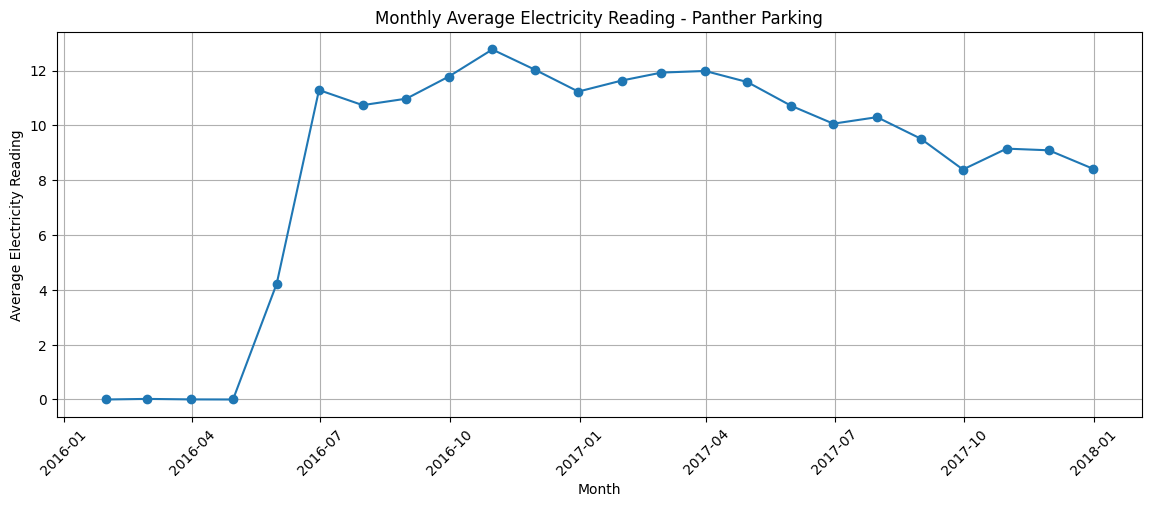

In [37]:
plt.figure(figsize=(14, 5))

plt.plot(monthly_average.index, monthly_average.values, marker='o')

plt.xlabel("Month")
plt.ylabel("Average Electricity Reading")
plt.title("Monthly Average Electricity Reading - Panther Parking")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [38]:
# Select all electricity meter columns
energy_data = df.drop(columns=["timestamp"])

# Display the first five rows
energy_data.head()

,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,Panther_retail_Gilbert,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,123.200,727.575,69.200,8.8224,370.0870,10.0,282.9965,26.0,135.0,168.2243
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,126.475,731.200,66.275,17.6449,737.8260,30.0,574.9265,51.0,265.0,336.4486
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,127.825,724.675,64.675,17.6449,729.9255,30.0,570.2780,50.0,272.0,336.4486
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,130.475,737.375,65.875,17.6449,722.2620,20.0,561.1470,52.0,276.0,336.4486
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,129.675,721.150,66.275,17.6449,719.1665,30.0,564.3695,50.0,280.0,336.4486


In [39]:
# Calculate statistics for all meters
meter_summary = energy_data.describe()

# Display the summary
meter_summary

,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,Panther_retail_Gilbert,...,Cockatoo_public_Caleb,Cockatoo_education_Tyler,Cockatoo_public_Shad,Mouse_health_Buddy,Mouse_health_Modesto,Mouse_lodging_Vicente,Mouse_health_Justin,Mouse_health_Ileana,Mouse_health_Estela,Mouse_science_Micheal
count,17533.000000,17533.000000,17532.000000,17532.000000,17533.000000,17534.000000,17533.000000,17533.000000,17524.000000,17532.000000,...,16110.000000,16116.000000,16113.000000,17483.000000,17540.000000,17544.000000,17544.000000,17379.000000,17544.000000,17544.000000
mean,8.661108,109.326952,5.396102,113.520501,126.329541,392.126185,96.513085,21.725700,27.257845,0.594539,...,181.787028,770.348807,129.774161,6.134131,482.296901,41.447504,708.649868,39.434000,348.329542,180.161176
std,4.900062,56.498653,4.223728,61.636034,71.783004,195.116299,62.818199,13.532895,15.092654,0.408065,...,54.150864,47.807854,37.264065,8.463139,266.172973,18.780824,284.883572,23.680096,144.408599,263.682848
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,83.350000,548.800000,60.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.661300,108.270900,2.676500,89.937400,100.849500,444.385800,56.097800,16.003100,17.923500,0.330100,...,133.425000,734.568750,97.525000,0.000000,310.030500,30.000000,616.111250,25.000000,299.500000,0.000000
50%,9.601900,126.624400,4.761900,133.705800,141.866400,469.390600,96.100600,18.003500,34.646700,0.550100,...,172.487500,763.925000,126.550000,0.000000,433.645000,40.000000,727.702500,32.000000,337.897950,0.000000
75%,12.662500,145.278000,7.952000,158.270500,179.404600,498.371200,148.136600,35.806900,39.047500,0.890200,...,228.875000,803.293750,158.825000,17.644900,671.243250,60.000000,870.693000,56.000000,438.000000,336.448600
max,25.497200,285.451200,27.770400,298.053200,375.038400,1052.711000,279.125900,54.804300,74.733100,1.520300,...,316.350000,925.550000,278.575000,40.816300,1267.846000,100.000000,1487.017000,126.000000,665.000000,2000.000000


In [40]:
# Find the meter with the highest average reading
highest_mean_meter = meter_summary.loc["mean"].idxmax()

# Find the meter with the lowest average reading
lowest_mean_meter = meter_summary.loc["mean"].idxmin()

print("Highest average meter:", highest_mean_meter)
print("Highest average:", meter_summary.loc["mean"].max())

print("Lowest average meter:", lowest_mean_meter)
print("Lowest average:", meter_summary.loc["mean"].min())

Highest average meter: Hog_education_Janell
Highest average: 3419.8882651605904
Lowest average meter: Hog_assembly_Marilynn
Lowest average: 0.0


In [41]:
# Display statistics for the highest-average meter
meter_summary[highest_mean_meter]

,Hog_education_Janell
count,17529.000000
mean,3419.888265
std,1218.640992
min,0.000000
25%,2582.000000
50%,3017.600000
75%,3737.700000
max,8894.000000


In [42]:
meter_summary[lowest_mean_meter]

,Hog_assembly_Marilynn
count,17544.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


In [43]:
# Check whether every reading in each meter is zero
constant_zero_meters = energy_data.columns[
    (energy_data == 0).all()
]

print("Number of constant-zero meters:", len(constant_zero_meters))

print(constant_zero_meters.tolist())

Number of constant-zero meters: 4
['Hog_assembly_Marilynn', 'Hog_assembly_Una', 'Hog_assembly_Arlie', 'Eagle_assembly_Noel']


In [44]:
constant_meters = energy_data.columns[
    energy_data.nunique() == 1
]

print("Number of constant meters:", len(constant_meters))
print(constant_meters.tolist())

Number of constant meters: 4
['Hog_assembly_Marilynn', 'Hog_assembly_Una', 'Hog_assembly_Arlie', 'Eagle_assembly_Noel']


In [45]:
missing_percentage = energy_data.isnull().mean() * 100

high_missing_meters = missing_percentage[
    missing_percentage > 20
]

print("Meters with more than 20% missing data:",
      len(high_missing_meters))

Meters with more than 20% missing data: 104


In [46]:
most_missing_meter = missing_percentage.idxmax()
highest_missing_percentage = missing_percentage.max()

print("Meter:", most_missing_meter)
print("Missing percentage:", highest_missing_percentage)

Meter: Rat_public_Ulysses
Missing percentage: 100.0


In [47]:
completely_empty_meters = energy_data.columns[
    energy_data.isnull().all()
]

print("Completely empty meters:", len(completely_empty_meters))
print(completely_empty_meters.tolist())

Completely empty meters: 2
['Rat_public_Ulysses', 'Eagle_lodging_Garland']


In [48]:
energy_data.drop(
    columns=completely_empty_meters,
    inplace=True
)

print("Updated dataset shape:", energy_data.shape)


Updated dataset shape: (17544, 1576)


In [49]:
missing_percentage = energy_data.isnull().mean() * 100

print(missing_percentage.describe())

count    1576.000000
mean        4.618580
std        13.329555
min         0.000000
25%         0.005700
50%         0.148199
75%         0.914843
max        99.373005
dtype: float64


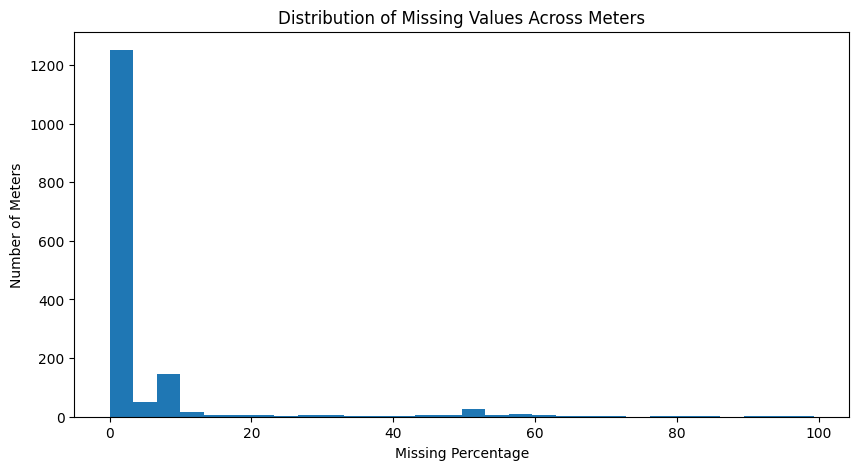

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(missing_percentage, bins=30)

plt.xlabel("Missing Percentage")
plt.ylabel("Number of Meters")
plt.title("Distribution of Missing Values Across Meters")

plt.show()

In [51]:
meter_name = "Panther_parking_Lorriane"

missing_count = energy_data[meter_name].isnull().sum()

missing_percent = (
    missing_count / len(energy_data)
) * 100

print("Meter:", meter_name)
print("Missing readings:", missing_count)
print("Missing percentage:", missing_percent)

Meter: Panther_parking_Lorriane
Missing readings: 11
Missing percentage: 0.06269949840401276


In [52]:
missing_timestamps = df.loc[
    energy_data[meter_name].isnull(),
    "timestamp"
]

print(missing_timestamps)

9860    2017-02-14 20:00:00
9861    2017-02-14 21:00:00
9862    2017-02-14 22:00:00
9863    2017-02-14 23:00:00
10466   2017-03-12 02:00:00
12859   2017-06-19 19:00:00
12860   2017-06-19 20:00:00
12861   2017-06-19 21:00:00
12862   2017-06-19 22:00:00
12863   2017-06-19 23:00:00
12864   2017-06-20 00:00:00
Name: timestamp, dtype: datetime64[ns]


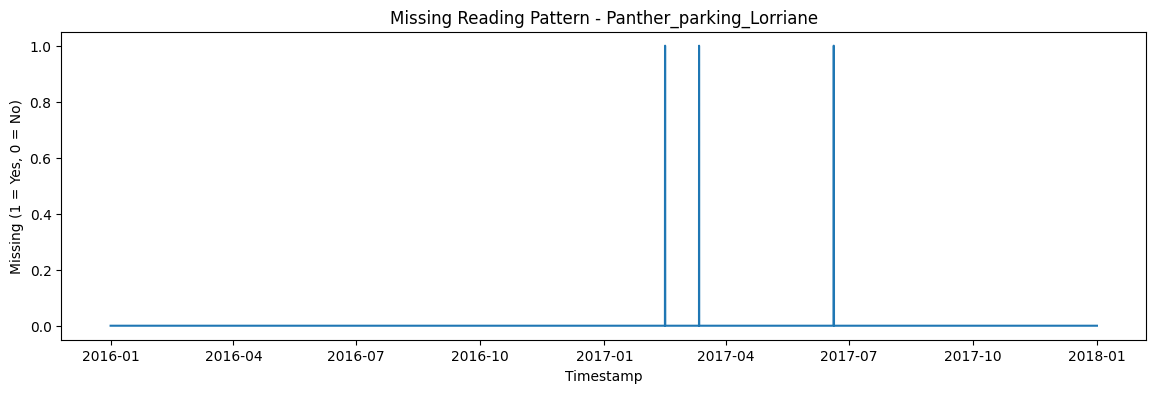

In [53]:
plt.figure(figsize=(14, 4))

plt.plot(
    df["timestamp"],
    energy_data[meter_name].isnull().astype(int)
)

plt.xlabel("Timestamp")
plt.ylabel("Missing (1 = Yes, 0 = No)")
plt.title("Missing Reading Pattern - Panther_parking_Lorriane")

plt.show()

In [54]:
# Examine readings around the February missing period

feb_data = df.loc[9857:9866, ["timestamp", meter_name]]

print(feb_data)

               timestamp  Panther_parking_Lorriane
9857 2017-02-14 17:00:00                   10.5620
9858 2017-02-14 18:00:00                   15.8431
9859 2017-02-14 19:00:00                    3.7207
9860 2017-02-14 20:00:00                       NaN
9861 2017-02-14 21:00:00                       NaN
9862 2017-02-14 22:00:00                       NaN
9863 2017-02-14 23:00:00                       NaN
9864 2017-02-15 00:00:00                    9.5418
9865 2017-02-15 01:00:00                   12.9025
9866 2017-02-15 02:00:00                   12.5424


In [55]:
feb_data["interpolated"] = (
    feb_data[meter_name].interpolate(method="linear")
)

print(feb_data)

               timestamp  Panther_parking_Lorriane  interpolated
9857 2017-02-14 17:00:00                   10.5620      10.56200
9858 2017-02-14 18:00:00                   15.8431      15.84310
9859 2017-02-14 19:00:00                    3.7207       3.72070
9860 2017-02-14 20:00:00                       NaN       4.88492
9861 2017-02-14 21:00:00                       NaN       6.04914
9862 2017-02-14 22:00:00                       NaN       7.21336
9863 2017-02-14 23:00:00                       NaN       8.37758
9864 2017-02-15 00:00:00                    9.5418       9.54180
9865 2017-02-15 01:00:00                   12.9025      12.90250
9866 2017-02-15 02:00:00                   12.5424      12.54240


In [56]:
june_data = df.loc[12856:12868, ["timestamp", meter_name]]

print(june_data)

                timestamp  Panther_parking_Lorriane
12856 2017-06-19 16:00:00                    8.1616
12857 2017-06-19 17:00:00                    9.1217
12858 2017-06-19 18:00:00                    7.2014
12859 2017-06-19 19:00:00                       NaN
12860 2017-06-19 20:00:00                       NaN
12861 2017-06-19 21:00:00                       NaN
12862 2017-06-19 22:00:00                       NaN
12863 2017-06-19 23:00:00                       NaN
12864 2017-06-20 00:00:00                       NaN
12865 2017-06-20 01:00:00                    9.3018
12866 2017-06-20 02:00:00                   12.1823
12867 2017-06-20 03:00:00                   12.0623
12868 2017-06-20 04:00:00                   12.1823


In [57]:
june_data = june_data.copy()

june_data["interpolated"] = (
    june_data[meter_name].interpolate(method="linear")
)

print(june_data)

                timestamp  Panther_parking_Lorriane  interpolated
12856 2017-06-19 16:00:00                    8.1616      8.161600
12857 2017-06-19 17:00:00                    9.1217      9.121700
12858 2017-06-19 18:00:00                    7.2014      7.201400
12859 2017-06-19 19:00:00                       NaN      7.501457
12860 2017-06-19 20:00:00                       NaN      7.801514
12861 2017-06-19 21:00:00                       NaN      8.101571
12862 2017-06-19 22:00:00                       NaN      8.401629
12863 2017-06-19 23:00:00                       NaN      8.701686
12864 2017-06-20 00:00:00                       NaN      9.001743
12865 2017-06-20 01:00:00                    9.3018      9.301800
12866 2017-06-20 02:00:00                   12.1823     12.182300
12867 2017-06-20 03:00:00                   12.0623     12.062300
12868 2017-06-20 04:00:00                   12.1823     12.182300


In [58]:
total_missing = energy_data.isnull().sum().sum()

print("Total missing readings:", total_missing)

Total missing readings: 1277007


In [59]:
overall_missing_percentage = (
    total_missing / energy_data.size
) * 100

print("Overall missing percentage:",
      overall_missing_percentage)

Overall missing percentage: 4.618579739179345


In [60]:
good_quality = (missing_percentage < 5).sum()

moderate_missing = missing_percentage.between(5, 20).sum()

high_missing = (missing_percentage > 20).sum()

print("Good quality meters:", good_quality)
print("Moderate missing meters:", moderate_missing)
print("High missing meters:", high_missing)

Good quality meters: 1278
Moderate missing meters: 196
High missing meters: 102


In [61]:
top_missing_meters = missing_percentage.sort_values(
    ascending=False
).head(10)

print(top_missing_meters)

Bobcat_education_Barbra     99.373005
Bobcat_education_Seth       96.243730
Rat_education_Mac           94.795942
Rat_education_Angelica      91.375969
Rat_education_Kristie       91.102371
Rat_education_Chance        89.871181
Peacock_public_Linda        83.595531
Bobcat_public_Angie         83.008436
Bobcat_education_Emile      82.689238
Bobcat_education_Rodrick    77.599179
dtype: float64


In [62]:
meter = "Bobcat_education_Barbra"

valid_readings = energy_data[meter].notnull().sum()

total_readings = len(energy_data)

print("Valid readings:", valid_readings)
print("Total readings:", total_readings)
print("Missing readings:", total_readings - valid_readings)

Valid readings: 110
Total readings: 17544
Missing readings: 17434


In [63]:
very_high_missing = (missing_percentage > 80).sum()

print("Meters with more than 80% missing data:",
      very_high_missing)

Meters with more than 80% missing data: 9


In [64]:
no_missing_meters = (missing_percentage == 0).sum()

print("Meters with no missing values:", no_missing_meters)

Meters with no missing values: 373


In [65]:
low_missing = (
    (missing_percentage > 0) &
    (missing_percentage <= 5)
).sum()

print("Meters with 0–5% missing data:", low_missing)

Meters with 0–5% missing data: 905


In [66]:
low_missing_meters = missing_percentage[
    (missing_percentage > 0) &
    (missing_percentage <= 5)
].index

print(low_missing_meters[:10].tolist())

['Panther_parking_Lorriane', 'Panther_lodging_Cora', 'Panther_office_Hannah', 'Panther_lodging_Hattie', 'Panther_education_Teofila', 'Panther_education_Jerome', 'Panther_retail_Felix', 'Panther_parking_Asia', 'Panther_education_Misty', 'Panther_retail_Gilbert']


In [67]:
meter_name = "Panther_parking_Lorriane"

missing_timestamps = df.loc[
    df[meter_name].isnull(),
    "timestamp"
]

print("Missing timestamps:")
print(missing_timestamps)

Missing timestamps:
9860    2017-02-14 20:00:00
9861    2017-02-14 21:00:00
9862    2017-02-14 22:00:00
9863    2017-02-14 23:00:00
10466   2017-03-12 02:00:00
12859   2017-06-19 19:00:00
12860   2017-06-19 20:00:00
12861   2017-06-19 21:00:00
12862   2017-06-19 22:00:00
12863   2017-06-19 23:00:00
12864   2017-06-20 00:00:00
Name: timestamp, dtype: datetime64[ns]


In [68]:
start_time = "2017-06-19 16:00:00"
end_time = "2017-06-20 03:00:00"

june_check = meter_data[
    meter_data["timestamp"].between(start_time, end_time)
]

print(june_check)

                timestamp  Panther_parking_Lorriane
12856 2017-06-19 16:00:00                    8.1616
12857 2017-06-19 17:00:00                    9.1217
12858 2017-06-19 18:00:00                    7.2014
12859 2017-06-19 19:00:00                       NaN
12860 2017-06-19 20:00:00                       NaN
12861 2017-06-19 21:00:00                       NaN
12862 2017-06-19 22:00:00                       NaN
12863 2017-06-19 23:00:00                       NaN
12864 2017-06-20 00:00:00                       NaN
12865 2017-06-20 01:00:00                    9.3018
12866 2017-06-20 02:00:00                   12.1823
12867 2017-06-20 03:00:00                   12.0623


In [69]:
# Create a copy of the cleaned meter dataset
energy_data_original = energy_data.copy()

print("Original dataset shape:", energy_data_original.shape)
print("Total missing values:", energy_data_original.isnull().sum().sum())

Original dataset shape: (17544, 1576)
Total missing values: 1277007


In [70]:
missing_counts = energy_data.isnull().sum()

print(missing_counts.head(10))

Panther_parking_Lorriane     11
Panther_lodging_Cora         11
Panther_office_Hannah        12
Panther_lodging_Hattie       12
Panther_education_Teofila    11
Panther_education_Jerome     10
Panther_retail_Felix         11
Panther_parking_Asia         11
Panther_education_Misty      20
Panther_retail_Gilbert       12
dtype: int64


In [71]:
missing_percentages = (missing_counts / len(energy_data)) * 100

print(missing_percentages.head(10).round(3))

Panther_parking_Lorriane     0.063
Panther_lodging_Cora         0.063
Panther_office_Hannah        0.068
Panther_lodging_Hattie       0.068
Panther_education_Teofila    0.063
Panther_education_Jerome     0.057
Panther_retail_Felix         0.063
Panther_parking_Asia         0.063
Panther_education_Misty      0.114
Panther_retail_Gilbert       0.068
dtype: float64


In [72]:
missing_flags = energy_data.isnull().astype(int)

print(missing_flags.head())


   Panther_parking_Lorriane  Panther_lodging_Cora  Panther_office_Hannah  \
0                         0                     0                      0   
1                         0                     0                      0   
2                         0                     0                      0   
3                         0                     0                      0   
4                         0                     0                      0   

   Panther_lodging_Hattie  Panther_education_Teofila  \
0                       0                          0   
1                       0                          0   
2                       0                          0   
3                       0                          0   
4                       0                          0   

   Panther_education_Jerome  Panther_retail_Felix  Panther_parking_Asia  \
0                         0                     0                     0   
1                         0                     0       

In [73]:
total_flagged = missing_flags.sum().sum()
original_missing = energy_data_original.drop(
    columns=completely_empty_meters,
    errors='ignore'
).isnull().sum().sum()

print("Flagged missing values:", total_flagged)
print("Original missing values:", original_missing)

Flagged missing values: 1277007
Original missing values: 1277007


In [74]:
meter_name = "Panther_parking_Lorriane"

meter_test = energy_data[[meter_name]].copy()

meter_test["interpolated"] = (
    meter_test[meter_name].interpolate(method="linear")
)

print(meter_test[meter_test[meter_name].isnull()])

       Panther_parking_Lorriane  interpolated
9860                        NaN      4.884920
9861                        NaN      6.049140
9862                        NaN      7.213360
9863                        NaN      8.377580
10466                       NaN     13.022500
12859                       NaN      7.501457
12860                       NaN      7.801514
12861                       NaN      8.101571
12862                       NaN      8.401629
12863                       NaN      8.701686
12864                       NaN      9.001743


In [75]:
meter_name = "Panther_parking_Lorriane"

meter_test = energy_data[[meter_name]].copy()

meter_test["interpolated"] = (
    meter_test[meter_name].interpolate(method="linear")
)

print(meter_test[meter_test[meter_name].isnull()])

       Panther_parking_Lorriane  interpolated
9860                        NaN      4.884920
9861                        NaN      6.049140
9862                        NaN      7.213360
9863                        NaN      8.377580
10466                       NaN     13.022500
12859                       NaN      7.501457
12860                       NaN      7.801514
12861                       NaN      8.101571
12862                       NaN      8.401629
12863                       NaN      8.701686
12864                       NaN      9.001743


In [76]:
comparison = meter_data.copy()

comparison["interpolated"] = meter_test["interpolated"]

print(
    comparison[comparison[meter_name].isnull()]
)

                timestamp  Panther_parking_Lorriane  interpolated
9860  2017-02-14 20:00:00                       NaN      4.884920
9861  2017-02-14 21:00:00                       NaN      6.049140
9862  2017-02-14 22:00:00                       NaN      7.213360
9863  2017-02-14 23:00:00                       NaN      8.377580
10466 2017-03-12 02:00:00                       NaN     13.022500
12859 2017-06-19 19:00:00                       NaN      7.501457
12860 2017-06-19 20:00:00                       NaN      7.801514
12861 2017-06-19 21:00:00                       NaN      8.101571
12862 2017-06-19 22:00:00                       NaN      8.401629
12863 2017-06-19 23:00:00                       NaN      8.701686
12864 2017-06-20 00:00:00                       NaN      9.001743


In [77]:
remaining_missing = meter_test["interpolated"].isnull().sum()

filled_values = (
    meter_test[meter_name].isnull() &
    meter_test["interpolated"].notnull()
).sum()

print("Remaining missing values:", remaining_missing)
print("Successfully estimated values:", filled_values)

Remaining missing values: 0
Successfully estimated values: 11


In [78]:
# Forward fill
meter_test["forward_fill"] = (
    meter_test[meter_name].ffill()
)

# Median imputation
meter_median = meter_test[meter_name].median()

meter_test["median_fill"] = (
    meter_test[meter_name].fillna(meter_median)
)

print("Median reading:", meter_median)

Median reading: 9.6019


In [79]:
june_comparison = meter_test.loc[
    12859:12864,
    [meter_name, "interpolated", "forward_fill", "median_fill"]
]

print(june_comparison)

       Panther_parking_Lorriane  interpolated  forward_fill  median_fill
12859                       NaN      7.501457        7.2014       9.6019
12860                       NaN      7.801514        7.2014       9.6019
12861                       NaN      8.101571        7.2014       9.6019
12862                       NaN      8.401629        7.2014       9.6019
12863                       NaN      8.701686        7.2014       9.6019
12864                       NaN      9.001743        7.2014       9.6019


In [80]:
low_group = (missing_percentage <= 5).sum()

moderate_group = (
    (missing_percentage > 5) &
    (missing_percentage <= 20)
).sum()

high_group = (missing_percentage > 20).sum()

print("Low missingness:", low_group)
print("Moderate missingness:", moderate_group)
print("High missingness:", high_group)

Low missingness: 1278
Moderate missingness: 196
High missingness: 102


In [81]:
high_missing_meters = missing_percentage[
    missing_percentage > 20
].index.tolist()

print("Number of high-missing meters:", len(high_missing_meters))
print("First 15 meters:", high_missing_meters[:15])

Number of high-missing meters: 102
First 15 meters: ['Panther_education_Quintin', 'Panther_office_Otto', 'Robin_office_Erma', 'Fox_education_Vernon', 'Fox_education_Maureen', 'Rat_education_Willy', 'Rat_education_Edmund', 'Rat_education_Donnell', 'Rat_education_Moises', 'Rat_office_Chris', 'Rat_public_Yetta', 'Rat_education_Roxanne', 'Rat_health_Ann', 'Rat_education_Matt', 'Rat_education_Penny']


In [82]:
# Identify meters with more than 80% missing data
very_high_missing = missing_percentage[missing_percentage > 80].index

# Identify constant-value meters
constant_meters = energy_data.nunique()[energy_data.nunique() == 1].index

# Combine columns to exclude
columns_to_exclude = very_high_missing.union(constant_meters)

# Create modelling dataset
clean_data = energy_data.drop(columns=columns_to_exclude).copy()

# Check results
print("Original shape:", energy_data.shape)
print("Excluded meters:", len(columns_to_exclude))
print("Cleaned shape:", clean_data.shape)
print("Remaining missing values:", clean_data.isnull().sum().sum())

Original shape: (17544, 1576)
Excluded meters: 13
Cleaned shape: (17544, 1563)
Remaining missing values: 1134540


In [83]:
# Preserve the selected dataset
clean_data_original = clean_data.copy()

# Add timestamps to the modelling dataset
clean_data = clean_data.copy()
clean_data["timestamp"] = df["timestamp"]

# Set timestamp as index
clean_data = clean_data.set_index("timestamp")

# Apply time-based interpolation
clean_data = clean_data.interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

# Check the results
print("Dataset shape:", clean_data.shape)
print("Remaining missing values:", clean_data.isnull().sum().sum())
print("Missing percentage:",
      round(clean_data.isnull().mean().mean() * 100, 2), "%")

Dataset shape: (17544, 1563)
Remaining missing values: 1104277
Missing percentage: 4.03 %


In [84]:
# Missing values for each meter
remaining_missing = clean_data.isnull().sum()

# Percentage of missing values for each meter
remaining_missing_percentage = (
    clean_data.isnull().mean() * 100
)

# Combine the results into one summary
missing_summary = pd.DataFrame({
    "Missing_Count": remaining_missing,
    "Missing_Percentage": remaining_missing_percentage
})

# Sort meters by highest missing percentage
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Count timestamps that still contain missing readings
timestamps_with_missing = clean_data.isnull().any(axis=1).sum()

print("Total remaining missing values:",
      clean_data.isnull().sum().sum())

print("Meters with remaining missing values:",
      (remaining_missing > 0).sum())

print("Timestamps with missing readings:",
      timestamps_with_missing)

print("\nTop 15 meters with remaining missing values:")
display(missing_summary.head(15))

Total remaining missing values: 1104277
Meters with remaining missing values: 837
Timestamps with missing readings: 17544

Top 15 meters with remaining missing values:


,Missing_Count,Missing_Percentage
Bobcat_education_Rodrick,13611,77.582079
Rat_education_Veronica,13578,77.393981
Rat_education_Moises,12525,71.391929
Rat_education_Abigail,12069,68.792750
Rat_public_Percy,11976,68.262654
Rat_education_Alonzo,11952,68.125855
Peacock_office_Naomi,11849,67.538760
Rat_education_Penny,11181,63.731190
Rat_education_Roxanne,11013,62.773598
Rat_public_Alexander,10861,61.907205


In [85]:
# Calculate missing percentage for every meter
missing_percent = clean_data.isnull().mean() * 100

# Categorize meters by missing percentage
print("Meters with 0% missing:", (missing_percent == 0).sum())
print("Meters with up to 5% missing:", (missing_percent <= 5).sum())
print("Meters with 5–20% missing:",
      ((missing_percent > 5) & (missing_percent <= 20)).sum())
print("Meters with 20–80% missing:",
      ((missing_percent > 20) & (missing_percent <= 80)).sum())

# Select meters with no more than 5% missing values
eligible_meters = missing_percent[missing_percent <= 5].index

# Calculate standard deviation for eligible meters
meter_variability = clean_data[eligible_meters].std()

# Create a ranking table
meter_selection = pd.DataFrame({
    "Missing_Percentage": missing_percent[eligible_meters],
    "Standard_Deviation": meter_variability
})

# Exclude constant-value meters
meter_selection = meter_selection[
    meter_selection["Standard_Deviation"] > 0
]

# Rank by variability
meter_selection = meter_selection.sort_values(
    by="Standard_Deviation",
    ascending=False
)

print("\nNumber of eligible meters:", len(meter_selection))
print("\nTop 15 candidate meters:")
display(meter_selection.head(15))

Meters with 0% missing: 726
Meters with up to 5% missing: 1280
Meters with 5–20% missing: 190
Meters with 20–80% missing: 93

Number of eligible meters: 1280

Top 15 candidate meters:


,Missing_Percentage,Standard_Deviation
Bull_education_Dottie,0.000000,2330.164083
Hog_education_Janell,0.034200,1224.029867
Moose_education_Leland,0.113999,1039.735080
Hog_office_Nia,1.345189,957.816171
Moose_education_Diane,3.471272,746.753561
Bull_education_Delia,0.000000,738.952030
Hog_education_Caridad,0.398997,683.108478
Hog_office_Joey,0.000000,542.454069
Hog_office_Terry,0.000000,519.932991
Rat_office_Jamal,0.000000,514.049566


In [86]:
# Identify all eligible meters
missing_percent = clean_data.isnull().mean() * 100

eligible_meters = missing_percent[
    missing_percent <= 5
].index.tolist()

# Prepare the modelling dataset
model_data = clean_data[eligible_meters].copy()

# Verify the dataset
print("Number of eligible meters:", len(eligible_meters))
print("Number of timestamps:", len(model_data))
print("Dataset shape:", model_data.shape)

print(
    "Memory usage:",
    round(model_data.memory_usage(deep=True).sum() / (1024**2), 2),
    "MB"
)

print("\nMissing values:", model_data.isnull().sum().sum())
print("\nSample data:")
display(model_data.iloc[:5, :5])

Number of eligible meters: 1280
Number of timestamps: 17544
Dataset shape: (17544, 1280)
Memory usage: 171.46 MB

Missing values: 54620

Sample data:


,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila
timestamp,,,,,
2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0


In [87]:
# Select a temporary batch of 50 meters
batch_meters = eligible_meters[:50]

# Create a copy of the selected readings
batch_data = model_data[batch_meters].copy()

# Extract time-based features
time_features = pd.DataFrame(index=batch_data.index)

time_features["hour"] = batch_data.index.hour
time_features["day_of_week"] = batch_data.index.dayofweek
time_features["month"] = batch_data.index.month
time_features["is_weekend"] = (
    batch_data.index.dayofweek >= 5
).astype(int)

# Generate lag features for every meter
lag_1 = batch_data.shift(1).add_suffix("_lag_1")
lag_24 = batch_data.shift(24).add_suffix("_lag_24")
lag_168 = batch_data.shift(168).add_suffix("_lag_168")

# Calculate historical rolling statistics
previous_readings = batch_data.shift(1)

rolling_mean_24 = (
    previous_readings.rolling(window=24, min_periods=24)
    .mean()
    .add_suffix("_rolling_mean_24")
)

rolling_std_24 = (
    previous_readings.rolling(window=24, min_periods=24)
    .std()
    .add_suffix("_rolling_std_24")
)

# Calculate deviation from recent average
deviation_24 = (
    batch_data - rolling_mean_24.set_axis(batch_data.columns, axis=1)
).add_suffix("_deviation_24")

# Combine all engineered features
feature_data = pd.concat(
    [
        batch_data,
        time_features,
        lag_1,
        lag_24,
        lag_168,
        rolling_mean_24,
        rolling_std_24,
        deviation_24
    ],
    axis=1
)

# Inspect the result
print("Original batch shape:", batch_data.shape)
print("Engineered feature shape:", feature_data.shape)

display(feature_data.head(30))

Original batch shape: (17544, 50)
Engineered feature shape: (17544, 354)


,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila,Panther_education_Jerome,Panther_retail_Felix,Panther_parking_Asia,Panther_education_Misty,Panther_retail_Gilbert,...,Panther_education_Hugh_deviation_24,Panther_lodging_Marisol_deviation_24,Panther_other_Bettie_deviation_24,Panther_office_Jesus_deviation_24,Panther_office_Taryn_deviation_24,Panther_education_Annetta_deviation_24,Panther_lodging_Janice_deviation_24,Panther_education_Ivan_deviation_24,Panther_education_Alecia_deviation_24,Panther_office_Christian_deviation_24
timestamp,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 05:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 06:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 07:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-01 08:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [88]:
# Convert original readings into long format
base = batch_data.stack(dropna=False).rename("reading").reset_index()

base.columns = ["timestamp", "meter", "reading"]

# Convert lag features into long format
lag1 = lag_1.stack(dropna=False).rename("lag_1").reset_index()
lag24 = lag_24.stack(dropna=False).rename("lag_24").reset_index()
lag168 = lag_168.stack(dropna=False).rename("lag_168").reset_index()

# Convert rolling statistics into long format
roll_mean = rolling_mean_24.stack(dropna=False).rename(
    "rolling_mean_24"
).reset_index()

roll_std = rolling_std_24.stack(dropna=False).rename(
    "rolling_std_24"
).reset_index()

# Convert deviation into long format
deviation = (
    deviation_24.stack(dropna=False)
    .rename("deviation_24")
    .reset_index()
)

# Standardize column names
for table in [lag1, lag24, lag168, roll_mean, roll_std, deviation]:
    table.columns = ["timestamp", "meter", table.columns[-1]]

# Merge the feature tables
long_features = base

for table in [lag1, lag24, lag168, roll_mean, roll_std, deviation]:
    long_features = long_features.merge(
        table,
        on=["timestamp", "meter"],
        how="left"
    )

# Add time-based features
long_features = long_features.merge(
    time_features.reset_index(),
    on="timestamp",
    how="left"
)

# Keep rows with valid current readings
long_features = long_features.dropna(subset=["reading"])

# Inspect
print("Long-format dataset shape:", long_features.shape)
print("Number of meters:", long_features["meter"].nunique())
display(long_features.head())


/tmp/ipykernel_756/570195333.py:2: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  base = batch_data.stack(dropna=False).rename("reading").reset_index()
/tmp/ipykernel_756/570195333.py:7: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  lag1 = lag_1.stack(dropna=False).rename("lag_1").reset_index()
/tmp/ipykernel_756/570195333.py:8: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this

Long-format dataset shape: (876839, 13)
Number of meters: 50


,timestamp,meter,reading,lag_1,lag_24,lag_168,rolling_mean_24,rolling_std_24,deviation_24,hour,day_of_week,month,is_weekend
0,2016-01-01,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,4,1,0
1,2016-01-01,Panther_lodging_Cora,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,4,1,0
2,2016-01-01,Panther_office_Hannah,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,4,1,0
3,2016-01-01,Panther_lodging_Hattie,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,4,1,0
4,2016-01-01,Panther_education_Teofila,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,4,1,0


In [89]:
# Select one meter for validation
sample_meter = long_features["meter"].iloc[0]

# Display its first 30 chronological observations
sample_check = (
    long_features[long_features["meter"] == sample_meter]
    .sort_values("timestamp")
    .head(30)
)

display(sample_check[
    ["timestamp", "meter", "reading", "lag_1",
     "lag_24", "rolling_mean_24", "hour", "day_of_week"]
])

,timestamp,meter,reading,lag_1,lag_24,rolling_mean_24,hour,day_of_week
0,2016-01-01 00:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,0,4
50,2016-01-01 01:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,1,4
100,2016-01-01 02:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,2,4
150,2016-01-01 03:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,3,4
200,2016-01-01 04:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,4,4
250,2016-01-01 05:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,5,4
300,2016-01-01 06:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,6,4
350,2016-01-01 07:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,7,4
400,2016-01-01 08:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,8,4
450,2016-01-01 09:00:00,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,9,4


In [90]:
# Check time-based features
print("Time feature validation:")

display(
    long_features[
        ["timestamp", "hour", "day_of_week", "month", "is_weekend"]
    ].drop_duplicates("timestamp").head(5)
)

# Check lag and rolling calculations for one meter
sample_meter = "Panther_parking_Lorriane"

display(
    long_features[
        long_features["meter"] == sample_meter
    ][
        ["timestamp", "reading", "lag_1", "lag_24",
         "rolling_mean_24", "rolling_std_24"]
    ].sort_values("timestamp").iloc[20:30]
)

Time feature validation:


,timestamp,hour,day_of_week,month,is_weekend
0,2016-01-01 00:00:00,0,4,1,0
50,2016-01-01 01:00:00,1,4,1,0
100,2016-01-01 02:00:00,2,4,1,0
150,2016-01-01 03:00:00,3,4,1,0
200,2016-01-01 04:00:00,4,4,1,0


,timestamp,reading,lag_1,lag_24,rolling_mean_24,rolling_std_24
1000,2016-01-01 20:00:00,0.0,NaN,NaN,NaN,NaN
1050,2016-01-01 21:00:00,0.0,NaN,NaN,NaN,NaN
1100,2016-01-01 22:00:00,0.0,NaN,NaN,NaN,NaN
1150,2016-01-01 23:00:00,0.0,NaN,NaN,NaN,NaN
1200,2016-01-02 00:00:00,0.0,NaN,NaN,NaN,NaN
1250,2016-01-02 01:00:00,0.0,NaN,NaN,NaN,NaN
1300,2016-01-02 02:00:00,0.0,NaN,NaN,NaN,NaN
1350,2016-01-02 03:00:00,0.0,NaN,NaN,NaN,NaN
1400,2016-01-02 04:00:00,0.0,NaN,NaN,NaN,NaN
1450,2016-01-02 05:00:00,0.0,NaN,NaN,NaN,NaN


In [91]:
sample_meter = "Panther_parking_Lorriane"

display(
    long_features[
        long_features["meter"] == sample_meter
    ][
        [
            "timestamp",
            "reading",
            "lag_1",
            "lag_24",
            "rolling_mean_24",
            "rolling_std_24"
        ]
    ]
    .sort_values("timestamp")
    .iloc[20:30]
)

,timestamp,reading,lag_1,lag_24,rolling_mean_24,rolling_std_24
1000,2016-01-01 20:00:00,0.0,NaN,NaN,NaN,NaN
1050,2016-01-01 21:00:00,0.0,NaN,NaN,NaN,NaN
1100,2016-01-01 22:00:00,0.0,NaN,NaN,NaN,NaN
1150,2016-01-01 23:00:00,0.0,NaN,NaN,NaN,NaN
1200,2016-01-02 00:00:00,0.0,NaN,NaN,NaN,NaN
1250,2016-01-02 01:00:00,0.0,NaN,NaN,NaN,NaN
1300,2016-01-02 02:00:00,0.0,NaN,NaN,NaN,NaN
1350,2016-01-02 03:00:00,0.0,NaN,NaN,NaN,NaN
1400,2016-01-02 04:00:00,0.0,NaN,NaN,NaN,NaN
1450,2016-01-02 05:00:00,0.0,NaN,NaN,NaN,NaN


In [92]:
sample_meter = "Panther_parking_Lorriane"

print("Batch data:")
display(batch_data[[sample_meter]].head(5))

print("Lag 1:")
display(lag_1[[sample_meter + "_lag_1"]].head(5))

print("Index checks:")
print("batch_data index:", batch_data.index[:5])
print("lag_1 index:", lag_1.index[:5])
print("Same index:", batch_data.index.equals(lag_1.index))
print("Missing readings:", batch_data[sample_meter].isna().sum())

Batch data:


,Panther_parking_Lorriane
timestamp,
2016-01-01 00:00:00,0.0
2016-01-01 01:00:00,0.0
2016-01-01 02:00:00,0.0
2016-01-01 03:00:00,0.0
2016-01-01 04:00:00,0.0


Lag 1:


,Panther_parking_Lorriane_lag_1
timestamp,
2016-01-01 00:00:00,NaN
2016-01-01 01:00:00,0.0
2016-01-01 02:00:00,0.0
2016-01-01 03:00:00,0.0
2016-01-01 04:00:00,0.0


Index checks:
batch_data index: DatetimeIndex(['2016-01-01 00:00:00', '2016-01-01 01:00:00',
               '2016-01-01 02:00:00', '2016-01-01 03:00:00',
               '2016-01-01 04:00:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)
lag_1 index: DatetimeIndex(['2016-01-01 00:00:00', '2016-01-01 01:00:00',
               '2016-01-01 02:00:00', '2016-01-01 03:00:00',
               '2016-01-01 04:00:00'],
              dtype='datetime64[ns]', name='timestamp', freq=None)
Same index: True
Missing readings: 4


In [93]:
sample_meter = "Panther_parking_Lorriane"

check = pd.DataFrame({
    "reading": batch_data[sample_meter],
    "lag_1": lag_1[sample_meter + "_lag_1"],
    "lag_24": lag_24[sample_meter + "_lag_24"],
    "rolling_mean_24": rolling_mean_24[
        sample_meter + "_rolling_mean_24"
    ],
    "rolling_std_24": rolling_std_24[
        sample_meter + "_rolling_std_24"
    ]
})

display(check.iloc[22:28])

,reading,lag_1,lag_24,rolling_mean_24,rolling_std_24
timestamp,,,,,
2016-01-01 22:00:00,0.0,0.0,NaN,NaN,NaN
2016-01-01 23:00:00,0.0,0.0,NaN,NaN,NaN
2016-01-02 00:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-02 01:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-02 02:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-02 03:00:00,0.0,0.0,0.0,0.0,0.0


In [94]:
!pip install pyarrow -q

import os

output_folder = "/content/drive/MyDrive/energy_anomaly_features"
os.makedirs(output_folder, exist_ok=True)

print("Output folder ready:", output_folder)
print("Eligible meters:", len(eligible_meters))
print("Batch size:", 50)

Output folder ready: /content/drive/MyDrive/energy_anomaly_features
Eligible meters: 1280
Batch size: 50


In [96]:
# Give missing_flags the same timestamp index as model_data
missing_flags_time = missing_flags.copy()

missing_flags_time.index = model_data.index

# Verify alignment
print("Missing flags shape:", missing_flags_time.shape)
print("Model data shape:", model_data.shape)

print(
    "Indexes match:",
    missing_flags_time.index.equals(model_data.index)
)

print(
    "All eligible meters available:",
    set(eligible_meters).issubset(missing_flags_time.columns)
)

Missing flags shape: (17544, 1576)
Model data shape: (17544, 1280)
Indexes match: True
All eligible meters available: True


In [98]:
import pandas as pd
import numpy as np
import os

# Configuration
batch_size = 50

# Store the names of all generated files
saved_files = []

# Process all 1,280 eligible meters in batches
for start in range(0, len(eligible_meters), batch_size):

    batch_meters = eligible_meters[start:start + batch_size]

    # Select the current batch
    batch_data = model_data[batch_meters].copy()

    # Previous readings
    previous_readings = batch_data.shift(1)

    # Lag features
    lag_1 = batch_data.shift(1)
    lag_24 = batch_data.shift(24)
    lag_168 = batch_data.shift(168)

    # Rolling features based only on previous readings
    rolling_mean_24 = previous_readings.rolling(
        window=24, min_periods=24
    ).mean()

    rolling_std_24 = previous_readings.rolling(
        window=24, min_periods=24
    ).std()

    # Deviation from the previous 24-hour average
    deviation_24 = batch_data - rolling_mean_24

    # Original missing-value indicators
    original_missing = missing_flags_time.loc[
        batch_data.index, batch_meters
    ]

    # Convert each feature into long format
    feature_frames = {
        "reading": batch_data,
        "lag_1": lag_1,
        "lag_24": lag_24,
        "lag_168": lag_168,
        "rolling_mean_24": rolling_mean_24,
        "rolling_std_24": rolling_std_24,
        "deviation_24": deviation_24,
        "was_missing_original": original_missing
    }

    stacked_features = [
        frame.stack(dropna=False).rename(name)
        for name, frame in feature_frames.items()
    ]

    batch_long = pd.concat(stacked_features, axis=1)

    # Convert timestamp and meter index into regular columns
    batch_long = batch_long.rename_axis(
        index=["timestamp", "meter"]
    ).reset_index()

    # Add time-based features
    batch_long["hour"] = batch_long["timestamp"].dt.hour
    batch_long["day_of_week"] = batch_long["timestamp"].dt.dayofweek
    batch_long["month"] = batch_long["timestamp"].dt.month
    batch_long["is_weekend"] = (
        batch_long["day_of_week"] >= 5
    ).astype("int8")

    # Save the current batch
    file_name = f"features_batch_{start // batch_size + 1:02d}.parquet"
    file_path = os.path.join(output_folder, file_name)

    batch_long.to_parquet(file_path, index=False)

    saved_files.append(file_path)

    print(
        f"Completed batch {start // batch_size + 1}: "
        f"{len(batch_meters)} meters | "
        f"{len(batch_long):,} rows"
    )

    # Release temporary data
    del batch_data, batch_long, stacked_features, feature_frames
    del previous_readings, lag_1, lag_24, lag_168
    del rolling_mean_24, rolling_std_24, deviation_24
    del original_missing

print("\nFEATURE ENGINEERING COMPLETED")
print("Total batches:", len(saved_files))
print("Total eligible meters:", len(eligible_meters))
print("Saved files:", output_folder)

/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/

Completed batch 1: 50 meters | 877,200 rows


/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/

Completed batch 2: 50 meters | 877,200 rows


/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/

Completed batch 3: 50 meters | 877,200 rows


... (42 outputs left out)

/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/

Completed batch 25: 50 meters | 877,200 rows


/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/tmp/ipykernel_756/606809627.py:57: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  frame.stack(dropna=False).rename(name)
/

Completed batch 26: 30 meters | 526,320 rows

FEATURE ENGINEERING COMPLETED
Total batches: 26
Total eligible meters: 1280
Saved files: /content/drive/MyDrive/energy_anomaly_features


In [99]:
import os
import pandas as pd

# List generated Parquet files
parquet_files = sorted([
    os.path.join(output_folder, file)
    for file in os.listdir(output_folder)
    if file.endswith(".parquet")
])

print("Total Parquet files:", len(parquet_files))

# Load the first batch for inspection
sample_features = pd.read_parquet(parquet_files[0])

print("\nFirst batch shape:", sample_features.shape)
print("\nColumns:")
print(sample_features.columns.tolist())

print("\nUnique meters in first batch:",
      sample_features["meter"].nunique())

print("\nDate range:",
      sample_features["timestamp"].min(),
      "to",
      sample_features["timestamp"].max())

display(sample_features.head())

Total Parquet files: 26

First batch shape: (877200, 14)

Columns:
['timestamp', 'meter', 'reading', 'lag_1', 'lag_24', 'lag_168', 'rolling_mean_24', 'rolling_std_24', 'deviation_24', 'was_missing_original', 'hour', 'day_of_week', 'month', 'is_weekend']

Unique meters in first batch: 50

Date range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00


,timestamp,meter,reading,lag_1,lag_24,lag_168,rolling_mean_24,rolling_std_24,deviation_24,was_missing_original,hour,day_of_week,month,is_weekend
0,2016-01-01,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4,1,0
1,2016-01-01,Panther_lodging_Cora,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4,1,0
2,2016-01-01,Panther_office_Hannah,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4,1,0
3,2016-01-01,Panther_lodging_Hattie,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4,1,0
4,2016-01-01,Panther_education_Teofila,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,4,1,0


In [100]:
import pandas as pd
import os

audit_results = []

for file in parquet_files:

    data = pd.read_parquet(file)

    audit_results.append({
        "file": os.path.basename(file),
        "rows": len(data),
        "unique_meters": data["meter"].nunique(),
        "unique_timestamps": data["timestamp"].nunique(),
        "duplicate_records": data.duplicated(
            subset=["timestamp", "meter"]
        ).sum(),
        "missing_readings": data["reading"].isna().sum(),
        "original_missing_count": data["was_missing_original"].sum(),
        "missing_lag_1": data["lag_1"].isna().sum(),
        "missing_lag_24": data["lag_24"].isna().sum(),
        "missing_lag_168": data["lag_168"].isna().sum()
    })

    del data

audit_df = pd.DataFrame(audit_results)

display(audit_df)

print("\nTOTAL ROWS:", audit_df["rows"].sum())
print("TOTAL METERS:", audit_df["unique_meters"].sum())
print("TOTAL DUPLICATES:", audit_df["duplicate_records"].sum())
print("TOTAL ORIGINAL MISSING READINGS:",
      audit_df["original_missing_count"].sum())

,file,rows,unique_meters,unique_timestamps,duplicate_records,missing_readings,original_missing_count,missing_lag_1,missing_lag_24,missing_lag_168
0,features_batch_01.parquet,877200,50,17544,0,361,723,411,1561,8761
1,features_batch_02.parquet,877200,50,17544,0,2017,2415,2065,3169,9997
2,features_batch_03.parquet,877200,50,17544,0,71,95,121,1271,8471
3,features_batch_04.parquet,877200,50,17544,0,336,1203,386,1536,8735
4,features_batch_05.parquet,877200,50,17544,0,188,1118,238,1388,8579
5,features_batch_06.parquet,877200,50,17544,0,704,1137,754,1904,9104
6,features_batch_07.parquet,877200,50,17544,0,6065,6776,6115,7265,14413
7,features_batch_08.parquet,877200,50,17544,0,4340,4990,4390,5540,12740
8,features_batch_09.parquet,877200,50,17544,0,3311,3909,3361,4511,11711
9,features_batch_10.parquet,877200,50,17544,0,5172,6019,5221,6348,13404



TOTAL ROWS: 22456320
TOTAL METERS: 1280
TOTAL DUPLICATES: 0
TOTAL ORIGINAL MISSING READINGS: 73476


In [101]:
# Inspect the first and fourteenth batches
batch_1 = pd.read_parquet(parquet_files[0])
batch_14 = pd.read_parquet(parquet_files[13])

check_columns = [
    "timestamp",
    "meter",
    "reading",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "was_missing_original"
]

print("BATCH 1 — First 5 rows")
display(batch_1[check_columns].head())

print("\nBATCH 14 — First 5 rows")
display(batch_14[check_columns].head())

print("\nMissing-value comparison")

for name, data in [
    ("Batch 1", batch_1),
    ("Batch 14", batch_14)
]:
    print(f"\n{name}")
    print(data[[
        "reading",
        "lag_1",
        "lag_24",
        "lag_168",
        "rolling_mean_24",
        "rolling_std_24",
        "deviation_24"
    ]].isna().sum())

BATCH 1 — First 5 rows


,timestamp,meter,reading,lag_1,lag_24,lag_168,rolling_mean_24,was_missing_original
0,2016-01-01,Panther_parking_Lorriane,0.0,NaN,NaN,NaN,NaN,0
1,2016-01-01,Panther_lodging_Cora,0.0,NaN,NaN,NaN,NaN,0
2,2016-01-01,Panther_office_Hannah,0.0,NaN,NaN,NaN,NaN,0
3,2016-01-01,Panther_lodging_Hattie,0.0,NaN,NaN,NaN,NaN,0
4,2016-01-01,Panther_education_Teofila,0.0,NaN,NaN,NaN,NaN,0



BATCH 14 — First 5 rows


,timestamp,meter,reading,lag_1,lag_24,lag_168,rolling_mean_24,was_missing_original
0,2016-01-01,Lamb_office_Raymond,2.5,NaN,NaN,NaN,NaN,0
1,2016-01-01,Lamb_assembly_Queen,0.4,NaN,NaN,NaN,NaN,0
2,2016-01-01,Lamb_education_Felipe,7.0,NaN,NaN,NaN,NaN,0
3,2016-01-01,Lamb_public_Gracie,0.9,NaN,NaN,NaN,NaN,0
4,2016-01-01,Lamb_assembly_Elinor,12.7,NaN,NaN,NaN,NaN,0



Missing-value comparison

Batch 1
reading             361
lag_1               411
lag_24             1561
lag_168            8761
rolling_mean_24    3930
rolling_std_24     3930
deviation_24       4033
dtype: int64

Batch 14
reading               0
lag_1                50
lag_24             1200
lag_168            8400
rolling_mean_24    1200
rolling_std_24     1200
deviation_24       1200
dtype: int64


In [102]:
# Define chronological split
all_timestamps = model_data.index.sort_values().unique()

split_position = int(len(all_timestamps) * 0.80)

train_end = all_timestamps[split_position - 1]
test_start = all_timestamps[split_position]

print("Training starts:", all_timestamps[0])
print("Training ends:", train_end)
print("Testing starts:", test_start)
print("Testing ends:", all_timestamps[-1])

print("Training hours:", split_position)
print("Testing hours:", len(all_timestamps) - split_position)

Training starts: 2016-01-01 00:00:00
Training ends: 2017-08-07 18:00:00
Testing starts: 2017-08-07 19:00:00
Testing ends: 2017-12-31 23:00:00
Training hours: 14035
Testing hours: 3509


In [103]:
# Select only the training period
training_data = model_data.loc[:train_end]

# Calculate statistics separately for every meter
meter_stats = pd.DataFrame({
    "mean": training_data.mean(),
    "std": training_data.std(),
    "median": training_data.median(),
    "min": training_data.min(),
    "max": training_data.max()
})

# Identify meters with zero or invalid standard deviation
zero_variance_meters = meter_stats[
    meter_stats["std"].isna() |
    (meter_stats["std"] == 0)
]

print("Meter statistics shape:", meter_stats.shape)

print("\nMeters with zero or invalid standard deviation:",
      len(zero_variance_meters))

print("\nSample meter statistics:")
display(meter_stats.head(10))

print("\nZero-variance meters:")
display(zero_variance_meters.head(10))

Meter statistics shape: (1280, 5)

Meters with zero or invalid standard deviation: 2

Sample meter statistics:


,mean,std,median,min,max
Panther_parking_Lorriane,8.615788,5.409788,10.2020,0.0,25.4972
Panther_lodging_Cora,102.313308,60.369689,124.1240,0.0,285.4512
Panther_office_Hannah,5.336185,4.406972,4.8529,0.0,27.7704
Panther_lodging_Hattie,110.294170,66.874962,134.8260,0.0,298.0532
Panther_education_Teofila,117.474278,75.257384,136.1763,0.0,375.0384
Panther_education_Jerome,368.337523,210.387038,465.9899,0.0,1052.7110
Panther_retail_Felix,93.746642,66.936704,94.2882,0.0,279.1259
Panther_parking_Asia,20.272136,14.034474,17.4033,0.0,54.8043
Panther_education_Misty,25.652965,15.948291,28.9656,0.0,74.7331
Panther_retail_Gilbert,0.567767,0.444090,0.5501,0.0,1.5203



Zero-variance meters:


,mean,std,median,min,max
Hog_office_Judith,0.0,0.0,0.0,0.0,0.0
Hog_assembly_Annemarie,0.0,0.0,0.0,0.0,0.0


In [104]:
# Calculate robust statistics using training data only
meter_stats["mad"] = (
    training_data
    .sub(meter_stats["median"], axis=1)
    .abs()
    .median()
)

# Identify meters suitable for standardization
valid_std = (
    meter_stats["std"].notna() &
    (meter_stats["std"] > 0)
)

# Identify meters suitable for robust standardization
valid_mad = (
    meter_stats["mad"].notna() &
    (meter_stats["mad"] > 0)
)

print("Meters with valid standard deviation:", valid_std.sum())
print("Meters with valid MAD:", valid_mad.sum())

print("\nRobust statistics:")
display(meter_stats.head(10))

Meters with valid standard deviation: 1278
Meters with valid MAD: 1265

Robust statistics:


,mean,std,median,min,max,mad
Panther_parking_Lorriane,8.615788,5.409788,10.2020,0.0,25.4972,3.0006
Panther_lodging_Cora,102.313308,60.369689,124.1240,0.0,285.4512,19.8538
Panther_office_Hannah,5.336185,4.406972,4.8529,0.0,27.7704,3.2467
Panther_lodging_Hattie,110.294170,66.874962,134.8260,0.0,298.0532,28.8856
Panther_education_Teofila,117.474278,75.257384,136.1763,0.0,375.0384,40.8399
Panther_education_Jerome,368.337523,210.387038,465.9899,0.0,1052.7110,33.2064
Panther_retail_Felix,93.746642,66.936704,94.2882,0.0,279.1259,54.7436
Panther_parking_Asia,20.272136,14.034474,17.4033,0.0,54.8043,17.4033
Panther_education_Misty,25.652965,15.948291,28.9656,0.0,74.7331,10.4820
Panther_retail_Gilbert,0.567767,0.444090,0.5501,0.0,1.5203,0.3701


In [105]:
import numpy as np
import pandas as pd

# Convert MAD into a robust estimate of standard deviation
meter_stats["robust_scale"] = 1.4826 * meter_stats["mad"]

# Use robust scale where valid; otherwise use standard deviation
meter_stats["scale"] = meter_stats["robust_scale"].where(
    meter_stats["robust_scale"] > 0,
    meter_stats["std"]
)

# Identify meters with a usable scale
valid_meters = meter_stats[
    meter_stats["scale"].notna() &
    (meter_stats["scale"] > 0)
].index

print("Meters with usable normalization:", len(valid_meters))
print("Meters excluded due to zero/invalid scale:",
      len(meter_stats) - len(valid_meters))

display(
    meter_stats.loc[valid_meters,
                    ["mean", "std", "median", "mad", "scale"]].head(10)
)

Meters with usable normalization: 1278
Meters excluded due to zero/invalid scale: 2


,mean,std,median,mad,scale
Panther_parking_Lorriane,8.615788,5.409788,10.2020,3.0006,4.448690
Panther_lodging_Cora,102.313308,60.369689,124.1240,19.8538,29.435244
Panther_office_Hannah,5.336185,4.406972,4.8529,3.2467,4.813557
Panther_lodging_Hattie,110.294170,66.874962,134.8260,28.8856,42.825791
Panther_education_Teofila,117.474278,75.257384,136.1763,40.8399,60.549236
Panther_education_Jerome,368.337523,210.387038,465.9899,33.2064,49.231809
Panther_retail_Felix,93.746642,66.936704,94.2882,54.7436,81.162861
Panther_parking_Asia,20.272136,14.034474,17.4033,17.4033,25.802133
Panther_education_Misty,25.652965,15.948291,28.9656,10.4820,15.540613
Panther_retail_Gilbert,0.567767,0.444090,0.5501,0.3701,0.548710


In [106]:
from pathlib import Path
import numpy as np
import pandas as pd

# Locate the 26 feature-engineering Parquet files
feature_folder = Path("/content/drive/MyDrive/energy_anomaly_features")
parquet_files = sorted(feature_folder.glob("*.parquet"))

print("Parquet files found:", len(parquet_files))

# Features that will be normalized
value_columns = [
    "reading",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_std_24",
    "deviation_24"
]

# Collect a representative training sample from every batch
train_samples = []

mean_map = meter_stats["mean"].to_dict()
scale_map = meter_stats["scale"].to_dict()

for file in parquet_files:

    batch = pd.read_parquet(file)

    # Keep training-period observations and usable meters
    batch = batch[
        (batch["timestamp"] <= train_end) &
        (batch["meter"].isin(valid_meters)) &
        (batch["was_missing_original"] == 0)
    ].copy()

    # Attach each meter's training statistics
    batch["meter_mean"] = batch["meter"].map(mean_map)
    batch["meter_scale"] = batch["meter"].map(scale_map)

    # Normalize readings relative to each meter
    for col in [
        "reading", "lag_1", "lag_24",
        "lag_168", "rolling_mean_24", "deviation_24"
    ]:
        batch[col + "_z"] = (
            batch[col] - batch["meter_mean"]
        ) / batch["meter_scale"]

    # Express rolling variation relative to meter scale
    batch["rolling_std_ratio"] = (
        batch["rolling_std_24"] / batch["meter_scale"]
    )

    # Encode cyclical time patterns
    batch["hour_sin"] = np.sin(2 * np.pi * batch["hour"] / 24)
    batch["hour_cos"] = np.cos(2 * np.pi * batch["hour"] / 24)

    batch["dow_sin"] = np.sin(2 * np.pi * batch["day_of_week"] / 7)
    batch["dow_cos"] = np.cos(2 * np.pi * batch["day_of_week"] / 7)

    batch["month_sin"] = np.sin(2 * np.pi * (batch["month"] - 1) / 12)
    batch["month_cos"] = np.cos(2 * np.pi * (batch["month"] - 1) / 12)

    # Select model features
    features = [
        "reading_z",
        "lag_1_z",
        "lag_24_z",
        "lag_168_z",
        "rolling_mean_24_z",
        "rolling_std_ratio",
        "deviation_24_z",
        "hour_sin",
        "hour_cos",
        "dow_sin",
        "dow_cos",
        "month_sin",
        "month_cos",
        "is_weekend"
    ]

    # Remove rows with incomplete model features
    batch = batch.dropna(subset=features)

    # Take 150 representative observations from each meter
    sampled = (
        batch.groupby("meter", group_keys=False)
        .sample(n=150, random_state=42)
    )

    train_samples.append(sampled[["meter", "timestamp"] + features])

# Combine all sampled batches
train_model_data = pd.concat(train_samples, ignore_index=True)

print("Training dataset shape:", train_model_data.shape)
print("Unique meters:", train_model_data["meter"].nunique())
print("Observations per meter:")
display(train_model_data.groupby("meter").size().describe())

display(train_model_data.head())

Parquet files found: 26
Training dataset shape: (191700, 16)
Unique meters: 1278
Observations per meter:


,0
count,1278.0
mean,150.0
std,0.0
min,150.0
25%,150.0
50%,150.0
75%,150.0
max,150.0


,meter,timestamp,reading_z,lag_1_z,lag_24_z,lag_168_z,rolling_mean_24_z,rolling_std_ratio,deviation_24_z,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,is_weekend
0,Panther_assembly_Carrol,2016-12-23 12:00:00,0.128786,-0.051075,0.209727,-0.149999,-0.323121,0.207069,-0.476007,1.224647e-16,-1.000000,-0.433884,-0.900969,-0.500000,0.866025,0
1,Panther_assembly_Carrol,2016-06-26 12:00:00,0.852739,0.645895,0.861735,0.920189,0.432871,0.497070,-0.508046,1.224647e-16,-1.000000,-0.781831,0.623490,0.500000,-0.866025,1
2,Panther_assembly_Carrol,2016-03-31 20:00:00,-0.927914,-0.927914,-0.927914,-0.927914,-0.927914,0.000000,-0.927914,-8.660254e-01,0.500000,0.433884,-0.900969,0.866025,0.500000,0
3,Panther_assembly_Carrol,2017-06-30 05:00:00,-0.451276,-0.455772,-0.388322,-0.329864,0.426500,0.549745,-1.805691,9.659258e-01,0.258819,-0.433884,-0.900969,0.500000,-0.866025,0
4,Panther_assembly_Carrol,2016-02-13 04:00:00,-0.927914,-0.927914,-0.927914,-0.927914,-0.927914,0.000000,-0.927914,8.660254e-01,0.500000,-0.974928,-0.222521,0.500000,0.866025,1


In [107]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest

# Select the 14 model features
feature_columns = [
    "reading_z", "lag_1_z", "lag_24_z", "lag_168_z",
    "rolling_mean_24_z", "rolling_std_ratio", "deviation_24_z",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "month_sin", "month_cos", "is_weekend"
]

X_train = train_model_data[feature_columns].copy()

# Validate data before training
print("Missing values:", X_train.isna().sum().sum())
print("Infinite values:", np.isinf(X_train.to_numpy()).sum())

assert np.isfinite(X_train.to_numpy()).all(), (
    "Fix missing or infinite values before training."
)

# Initialize and train Isolation Forest
isolation_model = IsolationForest(
    n_estimators=300,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(X_train)

# Predict training observations
train_predictions = isolation_model.predict(X_train)
train_scores = isolation_model.decision_function(X_train)

# Store predictions and scores
train_model_data["anomaly_prediction"] = train_predictions
train_model_data["anomaly_score"] = train_scores
train_model_data["is_anomaly"] = (
    train_predictions == -1
).astype(int)

# Display results
anomaly_count = train_model_data["is_anomaly"].sum()
normal_count = len(train_model_data) - anomaly_count

print("\nISOLATION FOREST TRAINING RESULTS")
print("---------------------------------")
print("Total observations:", len(train_model_data))
print("Normal observations:", normal_count)
print("Anomalous observations:", anomaly_count)
print("Training anomaly percentage:",
      round(anomaly_count / len(train_model_data) * 100, 2), "%")
print("Average anomaly score:", round(train_scores.mean(), 4))

Missing values: 0
Infinite values: 0

ISOLATION FOREST TRAINING RESULTS
---------------------------------
Total observations: 191700
Normal observations: 182115
Anomalous observations: 9585
Training anomaly percentage: 5.0 %
Average anomaly score: 0.0757


In [108]:
from pathlib import Path
import pandas as pd
import numpy as np

# Folder to store test predictions
test_folder = Path(
    "/content/drive/MyDrive/energy_anomaly_test_results"
)
test_folder.mkdir(parents=True, exist_ok=True)

test_summary = []

for file_number, file in enumerate(parquet_files, start=1):

    batch = pd.read_parquet(file)

    # Keep unseen-period observations from usable meters
    batch = batch[
        (batch["timestamp"] > train_end) &
        (batch["meter"].isin(valid_meters)) &
        (batch["was_missing_original"] == 0)
    ].copy()

    if batch.empty:
        continue

    # Apply training-period normalization statistics
    batch["meter_mean"] = batch["meter"].map(mean_map)
    batch["meter_scale"] = batch["meter"].map(scale_map)

    for col in [
        "reading", "lag_1", "lag_24",
        "lag_168", "rolling_mean_24", "deviation_24"
    ]:
        batch[col + "_z"] = (
            batch[col] - batch["meter_mean"]
        ) / batch["meter_scale"]

    batch["rolling_std_ratio"] = (
        batch["rolling_std_24"] / batch["meter_scale"]
    )

    # Apply the same cyclical time transformations
    batch["hour_sin"] = np.sin(2 * np.pi * batch["hour"] / 24)
    batch["hour_cos"] = np.cos(2 * np.pi * batch["hour"] / 24)

    batch["dow_sin"] = np.sin(
        2 * np.pi * batch["day_of_week"] / 7
    )
    batch["dow_cos"] = np.cos(
        2 * np.pi * batch["day_of_week"] / 7
    )

    batch["month_sin"] = np.sin(
        2 * np.pi * (batch["month"] - 1) / 12
    )
    batch["month_cos"] = np.cos(
        2 * np.pi * (batch["month"] - 1) / 12
    )

    # Keep only complete feature observations
    batch = batch.dropna(subset=feature_columns)

    if batch.empty:
        continue

    X_test_batch = batch[feature_columns]

    # Predict using the already-trained model
    batch["anomaly_prediction"] = isolation_model.predict(
        X_test_batch
    )

    batch["anomaly_score"] = isolation_model.decision_function(
        X_test_batch
    )

    batch["is_anomaly"] = (
        batch["anomaly_prediction"] == -1
    ).astype(int)

    # Save each batch separately
    output_file = test_folder / f"test_batch_{file_number}.parquet"

    batch[
        [
            "timestamp", "meter", "reading",
            "was_missing_original",
            "anomaly_prediction", "anomaly_score",
            "is_anomaly"
        ]
    ].to_parquet(output_file, index=False)

    test_summary.append({
        "batch": file_number,
        "observations": len(batch),
        "anomalies": batch["is_anomaly"].sum()
    })

# Combine summary information
test_summary_df = pd.DataFrame(test_summary)

total_test = test_summary_df["observations"].sum()
total_anomalies = test_summary_df["anomalies"].sum()

print("ISOLATION FOREST - TEST RESULTS")
print("--------------------------------")
print("Test observations:", total_test)
print("Normal observations:", total_test - total_anomalies)
print("Anomalous observations:", total_anomalies)
print(
    "Test anomaly percentage:",
    round(total_anomalies / total_test * 100, 2),
    "%"
)

print("\nBatch processing summary:")
display(test_summary_df.head())

ISOLATION FOREST - TEST RESULTS
--------------------------------
Test observations: 4452047
Normal observations: 4159154
Anomalous observations: 292893
Test anomaly percentage: 6.58 %

Batch processing summary:


,batch,observations,anomalies
0,1,175381,10962
1,2,173882,2084
2,3,175448,4771
3,4,173815,4538
4,5,174796,2789


In [109]:
from pathlib import Path
import pandas as pd

test_folder = Path(
    "/content/drive/MyDrive/energy_anomaly_test_results"
)

test_files = sorted(test_folder.glob("test_batch_*.parquet"))

meter_summaries = []

for file in test_files:

    batch = pd.read_parquet(file)

    summary = (
        batch.groupby("meter")
        .agg(
            total_observations=("is_anomaly", "count"),
            anomaly_count=("is_anomaly", "sum"),
            average_reading=("reading", "mean")
        )
        .reset_index()
    )

    meter_summaries.append(summary)

# Combine summaries from all batches
meter_summary = (
    pd.concat(meter_summaries, ignore_index=True)
    .groupby("meter", as_index=False)
    .sum(numeric_only=True)
)

# Calculate anomaly percentage for each meter
meter_summary["anomaly_percentage"] = (
    meter_summary["anomaly_count"] /
    meter_summary["total_observations"] * 100
)

# Sort meters by anomaly percentage
meter_summary = meter_summary.sort_values(
    "anomaly_percentage",
    ascending=False
)

print("Total meters evaluated:", len(meter_summary))

print("\nTOP 15 METERS BY ANOMALY PERCENTAGE")

display(meter_summary.head(15).round(2))

Total meters evaluated: 1278

TOP 15 METERS BY ANOMALY PERCENTAGE


,meter,total_observations,anomaly_count,average_reading,anomaly_percentage
950,Rat_assembly_Pam,3508,3508,3.25,100.00
989,Rat_education_Elsie,3508,3508,12.17,100.00
737,Lamb_office_Bertha,3509,3509,68.53,100.00
755,Lamb_public_Angeline,3509,3509,11.02,100.00
685,Lamb_education_Kasha,3509,3509,0.11,100.00
617,Lamb_assembly_Alden,3509,3509,0.00,100.00
639,Lamb_assembly_Rosa,3509,3509,130.62,100.00
645,Lamb_assembly_Zita,3509,3509,0.00,100.00
55,Bear_education_Santos,3416,3416,9.10,100.00
726,Lamb_education_Wilbert,3509,3503,0.18,99.83


In [110]:
# Identify the 15 highest-anomaly meters
top_meters = meter_summary.head(15)["meter"].tolist()

# Training behaviour of these meters
train_diagnostic = (
    train_model_data[
        train_model_data["meter"].isin(top_meters)
    ]
    .groupby("meter")
    .agg(
        train_observations=("is_anomaly", "count"),
        train_anomalies=("is_anomaly", "sum"),
        train_mean_reading_z=("reading_z", "mean"),
        train_mean_score=("anomaly_score", "mean"),
        train_median_score=("anomaly_score", "median")
    )
    .reset_index()
)

train_diagnostic["train_anomaly_percentage"] = (
    train_diagnostic["train_anomalies"] /
    train_diagnostic["train_observations"] * 100
)

# Test behaviour of the same meters
test_diagnostic_parts = []

for file in test_files:
    batch = pd.read_parquet(file)

    batch = batch[batch["meter"].isin(top_meters)]

    if not batch.empty:
        test_diagnostic_parts.append(
            batch.groupby("meter").agg(
                test_observations=("is_anomaly", "count"),
                test_anomalies=("is_anomaly", "sum"),
                test_average_reading=("reading", "mean"),
                test_mean_score=("anomaly_score", "mean"),
                test_median_score=("anomaly_score", "median"),
                test_min_score=("anomaly_score", "min"),
                test_max_score=("anomaly_score", "max")
            )
        )

test_diagnostic = (
    pd.concat(test_diagnostic_parts)
    .groupby("meter")
    .sum(numeric_only=True)
    .reset_index()
)

# Combine training and testing diagnostics
diagnostic_comparison = train_diagnostic.merge(
    test_diagnostic,
    on="meter",
    how="inner"
)

diagnostic_comparison = diagnostic_comparison.sort_values(
    "test_anomalies",
    ascending=False
)

display(diagnostic_comparison.round(4))

,meter,train_observations,train_anomalies,train_mean_reading_z,train_mean_score,train_median_score,train_anomaly_percentage,test_observations,test_anomalies,test_average_reading,test_mean_score,test_median_score,test_min_score,test_max_score
6,Lamb_assembly_Zita,150,150,-48.8146,-0.1749,-0.1639,100.0000,3509,3509,0.0002,-0.1613,-0.1614,-0.1801,-0.1419
5,Lamb_assembly_Rosa,150,149,0.5422,-0.0954,-0.0904,99.3333,3509,3509,130.6174,-0.1064,-0.1054,-0.1795,-0.0131
4,Lamb_assembly_Alden,150,48,-0.0220,0.0304,0.0541,32.0000,3509,3509,0.0001,-0.0504,-0.0477,-0.0790,-0.0292
10,Lamb_office_Bertha,150,150,-10.5454,-0.1658,-0.1471,100.0000,3509,3509,68.5328,-0.1838,-0.1950,-0.2169,-0.1216
11,Lamb_public_Angeline,150,150,14.8076,-0.1841,-0.1962,100.0000,3509,3509,11.0231,-0.1649,-0.1536,-0.2282,-0.1328
7,Lamb_education_Kasha,150,144,-0.7323,-0.0725,-0.0672,96.0000,3509,3509,0.1087,-0.0606,-0.0583,-0.0881,-0.0317
13,Rat_assembly_Pam,150,150,-0.1332,-0.0740,-0.0605,100.0000,3508,3508,3.2510,-0.0668,-0.0649,-0.0996,-0.0065
14,Rat_education_Elsie,150,150,2.0532,-0.0949,-0.0776,100.0000,3508,3508,12.1737,-0.0716,-0.0695,-0.0976,-0.0533
9,Lamb_education_Wilbert,150,148,0.0498,-0.0856,-0.0871,98.6667,3509,3503,0.1828,-0.0711,-0.0703,-0.0952,0.0241
8,Lamb_education_Marty,150,137,-0.0698,-0.0545,-0.0457,91.3333,3509,3501,0.0919,-0.0499,-0.0486,-0.0813,0.0118


In [111]:
# Calculate the 5th percentile score for every meter
meter_thresholds = (
    train_model_data
    .groupby("meter")["anomaly_score"]
    .quantile(0.05)
)

print("Meters with calibrated thresholds:", len(meter_thresholds))

display(
    meter_thresholds
    .rename("anomaly_threshold")
    .reset_index()
    .head(10)
)

Meters with calibrated thresholds: 1278


,meter,anomaly_threshold
0,Bear_assembly_Beatrice,-0.023778
1,Bear_assembly_Genia,0.020975
2,Bear_assembly_Jose,0.077709
3,Bear_assembly_Roxy,-0.005611
4,Bear_assembly_Ruby,0.058237
5,Bear_education_Alfredo,0.026697
6,Bear_education_Alvaro,0.063919
7,Bear_education_Arnold,-0.019572
8,Bear_education_Augusta,-0.004796
9,Bear_education_Austin,-0.015240


In [112]:
from pathlib import Path
import pandas as pd

calibrated_folder = Path(
    "/content/drive/MyDrive/energy_anomaly_calibrated"
)
calibrated_folder.mkdir(parents=True, exist_ok=True)

calibrated_summaries = []

for file_number, file in enumerate(test_files, start=1):

    batch = pd.read_parquet(file)

    # Assign the threshold belonging to each meter
    batch["meter_threshold"] = batch["meter"].map(
        meter_thresholds
    )

    # Classify using meter-specific thresholds
    batch["calibrated_anomaly"] = (
        batch["anomaly_score"] < batch["meter_threshold"]
    ).astype(int)

    # Save calibrated results separately
    output_file = (
        calibrated_folder /
        f"calibrated_batch_{file_number}.parquet"
    )

    batch.to_parquet(output_file, index=False)

    # Summarize each meter
    summary = (
        batch.groupby("meter")
        .agg(
            observations=("calibrated_anomaly", "count"),
            anomalies=("calibrated_anomaly", "sum")
        )
        .reset_index()
    )

    calibrated_summaries.append(summary)

# Combine summaries
calibrated_meter_summary = (
    pd.concat(calibrated_summaries, ignore_index=True)
    .groupby("meter", as_index=False)
    .sum(numeric_only=True)
)

calibrated_meter_summary["anomaly_percentage"] = (
    calibrated_meter_summary["anomalies"] /
    calibrated_meter_summary["observations"] * 100
)

print("CALIBRATED TEST RESULTS")
print("-----------------------")
print(
    "Total observations:",
    calibrated_meter_summary["observations"].sum()
)
print(
    "Total anomalies:",
    calibrated_meter_summary["anomalies"].sum()
)
print(
    "Overall anomaly percentage:",
    round(
        calibrated_meter_summary["anomalies"].sum() /
        calibrated_meter_summary["observations"].sum() * 100,
        2
    ),
    "%"
)

print("\nTOP 15 METERS AFTER CALIBRATION")

display(
    calibrated_meter_summary
    .sort_values("anomaly_percentage", ascending=False)
    .head(15)
    .round(2)
)

CALIBRATED TEST RESULTS
-----------------------
Total observations: 4452047
Total anomalies: 459338
Overall anomaly percentage: 10.32 %

TOP 15 METERS AFTER CALIBRATION


,meter,observations,anomalies,anomaly_percentage
117,Bull_education_Dottie,3506,3316,94.58
739,Lamb_office_Callie,3509,2804,79.91
1012,Rat_education_Marcos,3189,2502,78.46
1202,Robin_education_Takako,3509,2732,77.86
563,Hog_office_Marilyn,3509,2698,76.89
512,Hog_lodging_Edgar,3509,2653,75.61
542,Hog_office_Darline,3509,2589,73.78
472,Hog_assembly_Edward,3509,2426,69.14
1120,Rat_public_Fredrick,2764,1907,68.99
1141,Rat_public_Loretta,3189,2098,65.79


In [113]:
from pathlib import Path
import pandas as pd

# 1. Get the 15 meters with the highest calibrated anomaly rates
top_meters = (
    calibrated_meter_summary
    .nlargest(15, "anomaly_percentage")["meter"]
    .tolist()
)

# 2. Summarize training scores
train_comparison = (
    train_model_data[
        train_model_data["meter"].isin(top_meters)
    ]
    .groupby("meter")
    .agg(
        train_observations=("anomaly_score", "count"),
        train_median_score=("anomaly_score", "median"),
        train_5th_percentile=("anomaly_score",
                              lambda x: x.quantile(0.05))
    )
    .reset_index()
)

# 3. Read test scores for the same meters
test_parts = []

for file in test_files:
    batch = pd.read_parquet(file)

    batch = batch[batch["meter"].isin(top_meters)]

    if not batch.empty:
        summary = (
            batch.groupby("meter")
            .agg(
                test_observations=("anomaly_score", "count"),
                test_median_score=("anomaly_score", "median"),
                test_mean_score=("anomaly_score", "mean"),
                test_min_score=("anomaly_score", "min"),
                test_max_score=("anomaly_score", "max")
            )
            .reset_index()
        )

        test_parts.append(summary)

test_comparison = pd.concat(test_parts, ignore_index=True)

# 4. Combine training and testing statistics
score_comparison = train_comparison.merge(
    test_comparison,
    on="meter",
    how="inner"
)

# 5. Calculate the change in median score
score_comparison["median_score_change"] = (
    score_comparison["test_median_score"]
    - score_comparison["train_median_score"]
)

# 6. Add calibrated anomaly percentages
score_comparison = score_comparison.merge(
    calibrated_meter_summary[
        ["meter", "anomaly_percentage"]
    ],
    on="meter",
    how="left"
)

score_comparison = score_comparison.sort_values(
    "anomaly_percentage", ascending=False
)

display(score_comparison.round(4))

,meter,train_observations,train_median_score,train_5th_percentile,test_observations,test_median_score,test_mean_score,test_min_score,test_max_score,median_score_change,anomaly_percentage
0,Bull_education_Dottie,150,0.0715,0.0154,3506,-0.0384,-0.0390,-0.1635,0.0530,-0.1099,94.5807
8,Lamb_office_Callie,150,0.0946,0.0335,3509,0.0236,0.0268,-0.0183,0.1141,-0.0709,79.9088
11,Rat_education_Marcos,150,0.0935,0.0510,3189,0.0350,0.0339,-0.0231,0.0878,-0.0586,78.4572
14,Robin_education_Takako,150,0.0868,0.0601,3509,-0.0331,-0.0084,-0.0802,0.1029,-0.1199,77.8569
7,Hog_office_Marilyn,150,0.0873,0.0575,3509,0.0270,0.0324,-0.0261,0.1073,-0.0602,76.8880
3,Hog_lodging_Edgar,150,0.0915,0.0650,3509,0.0313,0.0375,-0.0156,0.0896,-0.0602,75.6056
6,Hog_office_Darline,150,0.0615,-0.0092,3509,-0.0199,-0.0220,-0.0908,0.0450,-0.0815,73.7817
2,Hog_assembly_Edward,150,0.0851,0.0478,3509,0.0300,0.0303,-0.0682,0.0941,-0.0551,69.1365
12,Rat_public_Fredrick,150,0.0783,0.0047,2764,-0.0287,-0.0179,-0.1052,0.0975,-0.1070,68.9942
13,Rat_public_Loretta,150,0.0860,0.0278,3189,0.0118,0.0164,-0.0386,0.0830,-0.0742,65.7886


In [114]:
# Select the five meters with the highest calibrated anomaly rates
diagnostic_meters = (
    calibrated_meter_summary
    .nlargest(5, "anomaly_percentage")["meter"]
    .tolist()
)

# Get actual training and testing electricity readings
training_readings = (
    model_data.loc[:train_end, diagnostic_meters]
)

testing_readings = (
    model_data.loc[test_start:, diagnostic_meters]
)

# Summarize the actual readings
def summarize_readings(data, period):
    summary = data.agg(["mean", "median", "std"]).T

    summary["zero_percentage"] = (
        data.eq(0).sum() / data.notna().sum() * 100
    )

    summary["period"] = period
    return summary.reset_index(names="meter")

reading_comparison = pd.concat([
    summarize_readings(training_readings, "Training"),
    summarize_readings(testing_readings, "Testing")
], ignore_index=True)

display(reading_comparison.round(3))

,meter,mean,median,std,zero_percentage,period
0,Bull_education_Dottie,1409.244,1390.000,1717.737,2.401,Training
1,Lamb_office_Callie,4.106,4.450,2.106,0.164,Training
2,Rat_education_Marcos,402.882,400.425,87.721,0.000,Training
3,Robin_education_Takako,178.514,173.600,37.498,0.000,Training
4,Hog_office_Marilyn,40.951,38.008,10.782,0.969,Training
5,Bull_education_Dottie,1008.095,963.000,3901.287,8.093,Testing
6,Lamb_office_Callie,0.456,0.001,1.385,0.627,Testing
7,Rat_education_Marcos,219.919,211.965,41.166,0.000,Testing
8,Robin_education_Takako,84.293,37.300,77.814,0.000,Testing
9,Hog_office_Marilyn,23.096,20.073,7.052,0.000,Testing


In [115]:
# Select the five meters
diagnostic_meters = [
    "Bull_education_Dottie",
    "Lamb_office_Callie",
    "Rat_education_Marcos",
    "Robin_education_Takako",
    "Hog_office_Marilyn"
]

# Extract their complete time series
monthly_data = model_data[diagnostic_meters].copy()

# Calculate monthly statistics
monthly_summary = (
    monthly_data
    .resample("MS")
    .agg(["mean", "median", "std"])
)

# Convert the results into a readable table
monthly_summary.columns = [
    f"{meter}_{stat}"
    for meter, stat in monthly_summary.columns
]

monthly_summary = monthly_summary.reset_index()

display(monthly_summary.round(2))

,timestamp,Bull_education_Dottie_mean,Bull_education_Dottie_median,Bull_education_Dottie_std,Lamb_office_Callie_mean,Lamb_office_Callie_median,Lamb_office_Callie_std,Rat_education_Marcos_mean,Rat_education_Marcos_median,Rat_education_Marcos_std,Robin_education_Takako_mean,Robin_education_Takako_median,Robin_education_Takako_std,Hog_office_Marilyn_mean,Hog_office_Marilyn_median,Hog_office_Marilyn_std
0,2016-01-01,1266.25,1242.5,1297.65,5.32,5.43,1.46,430.25,418.98,66.52,156.62,151.90,18.58,36.84,33.74,8.49
1,2016-02-01,1322.62,1295.0,1226.95,5.22,5.25,1.27,431.83,421.60,69.40,158.58,153.10,19.83,41.00,36.46,9.56
2,2016-03-01,1327.97,1310.0,414.57,4.93,4.91,1.21,378.11,382.60,52.77,153.75,147.80,18.44,39.42,35.70,8.94
3,2016-04-01,1350.51,1336.5,106.89,4.82,4.80,1.23,363.79,357.39,48.68,154.20,148.40,17.43,38.13,34.29,8.09
4,2016-05-01,1347.12,1334.0,277.00,4.86,4.82,1.29,373.44,364.12,71.95,149.11,145.75,16.13,38.86,37.31,7.26
5,2016-06-01,1392.11,1375.0,101.20,4.84,4.91,1.15,437.28,445.04,68.39,160.97,155.80,20.06,43.28,43.33,11.69
6,2016-07-01,1392.27,1432.0,1412.37,4.53,4.57,1.16,502.69,514.73,59.74,174.05,169.00,19.92,42.84,45.29,19.82
7,2016-08-01,1434.06,1426.0,94.64,4.67,4.61,1.04,491.30,497.20,82.73,168.01,162.75,24.32,49.90,46.87,10.00
8,2016-09-01,1504.00,1499.5,101.40,4.67,4.72,1.40,444.02,445.40,73.27,168.14,162.85,22.01,45.76,41.35,10.75
9,2016-10-01,1586.33,1434.0,3485.14,4.93,4.98,1.15,361.73,352.07,65.58,184.92,174.10,25.64,38.89,34.52,8.99


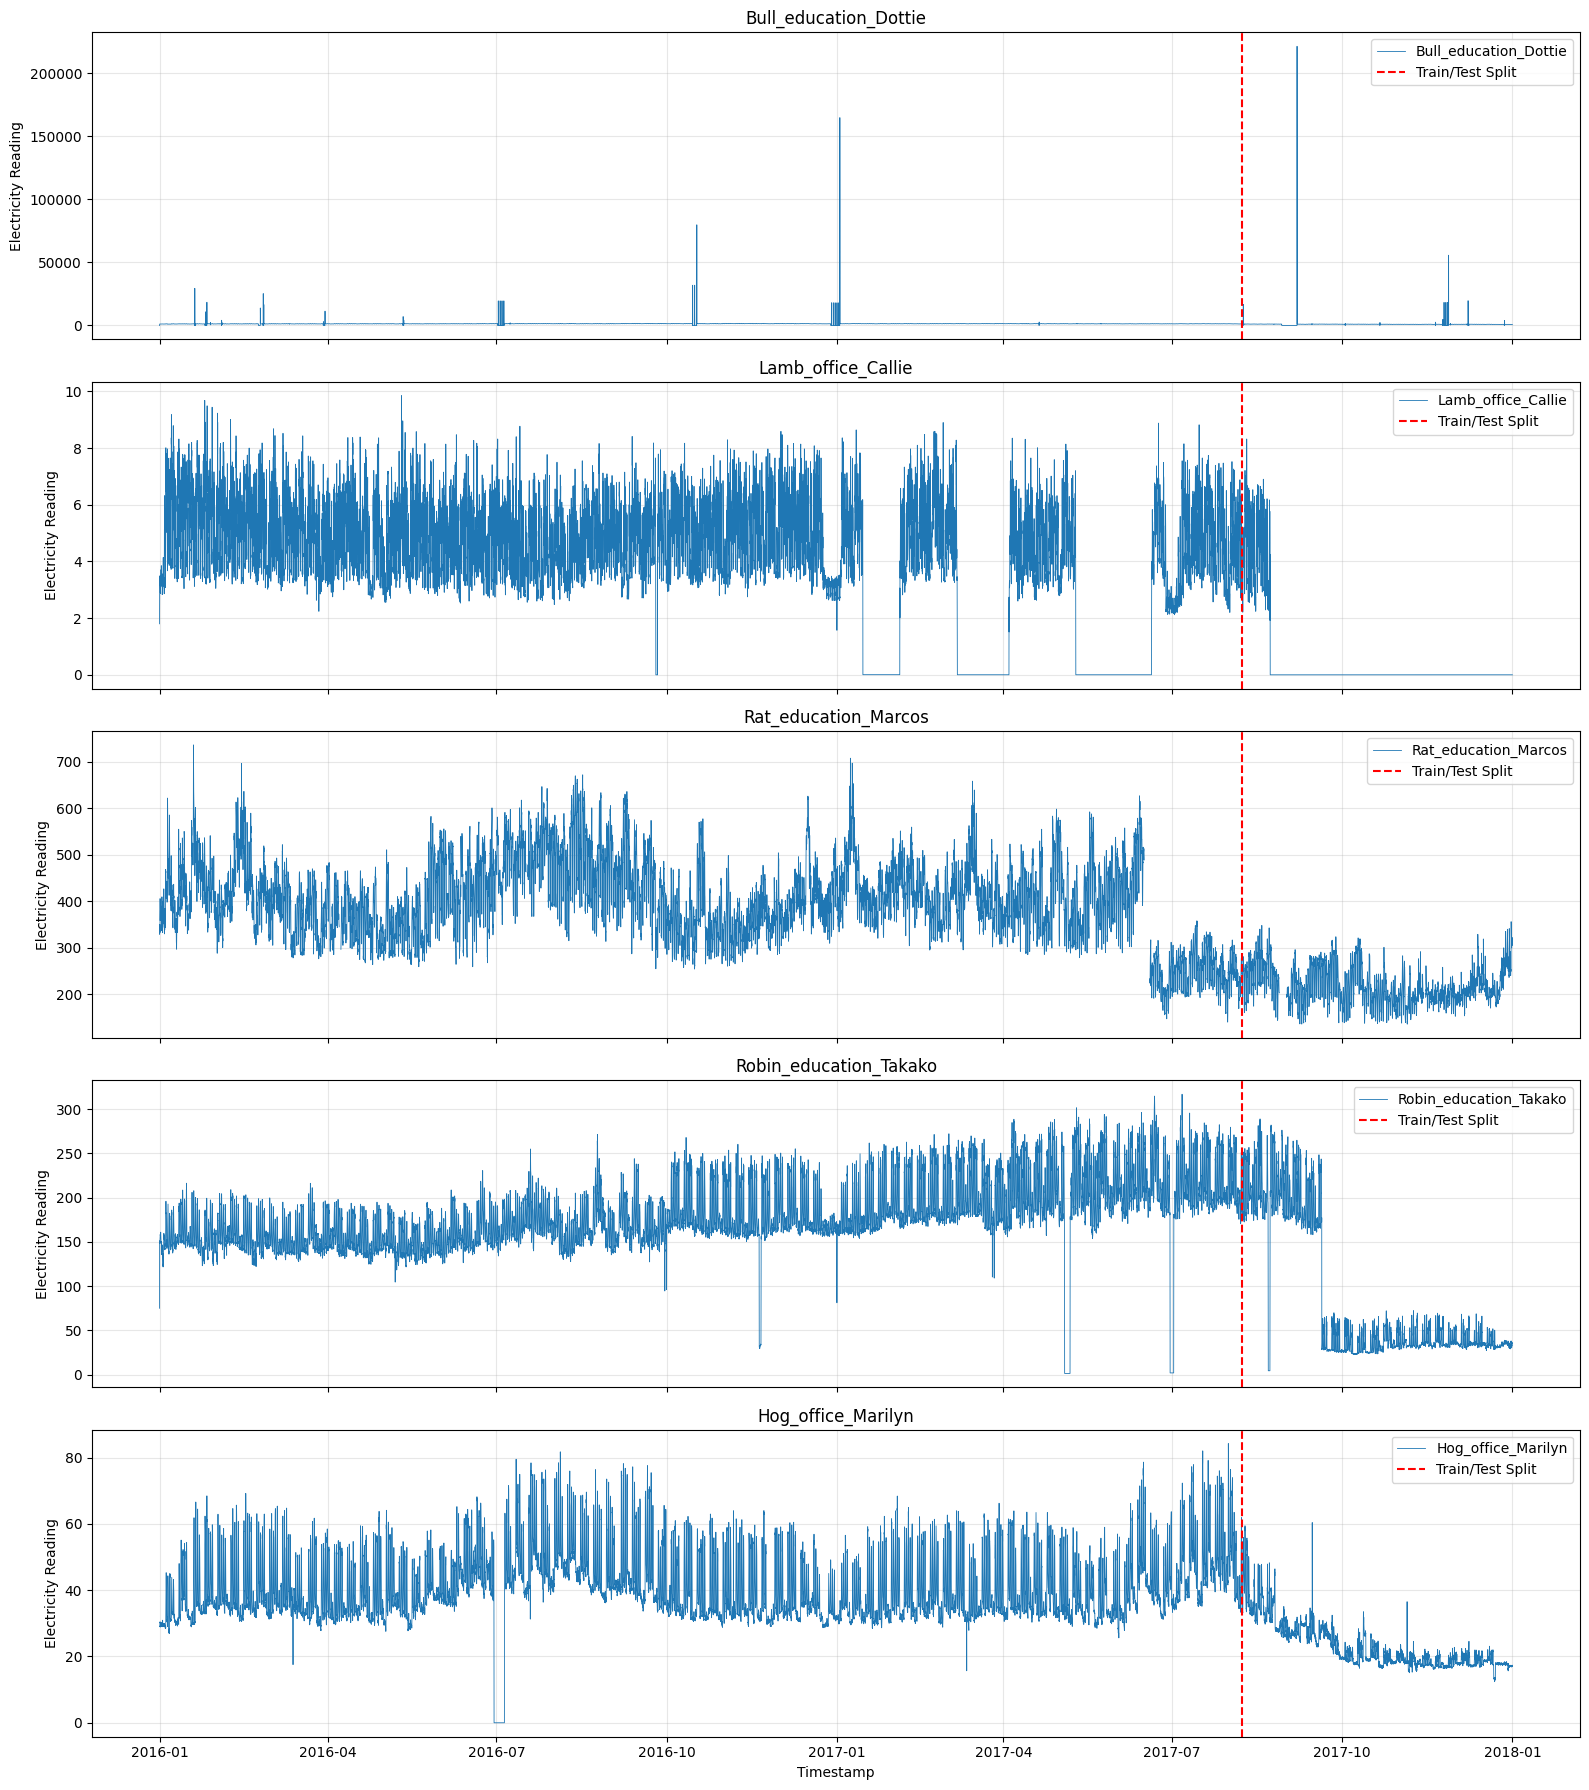

In [116]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 18),
    sharex=True
)

for ax, meter in zip(axes, diagnostic_meters):

    ax.plot(
        model_data.index,
        model_data[meter],
        linewidth=0.6,
        label=meter
    )

    ax.axvline(
        train_end,
        color="red",
        linestyle="--",
        label="Train/Test Split"
    )

    ax.set_title(meter)
    ax.set_ylabel("Electricity Reading")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

plt.xlabel("Timestamp")
plt.tight_layout()
plt.show()

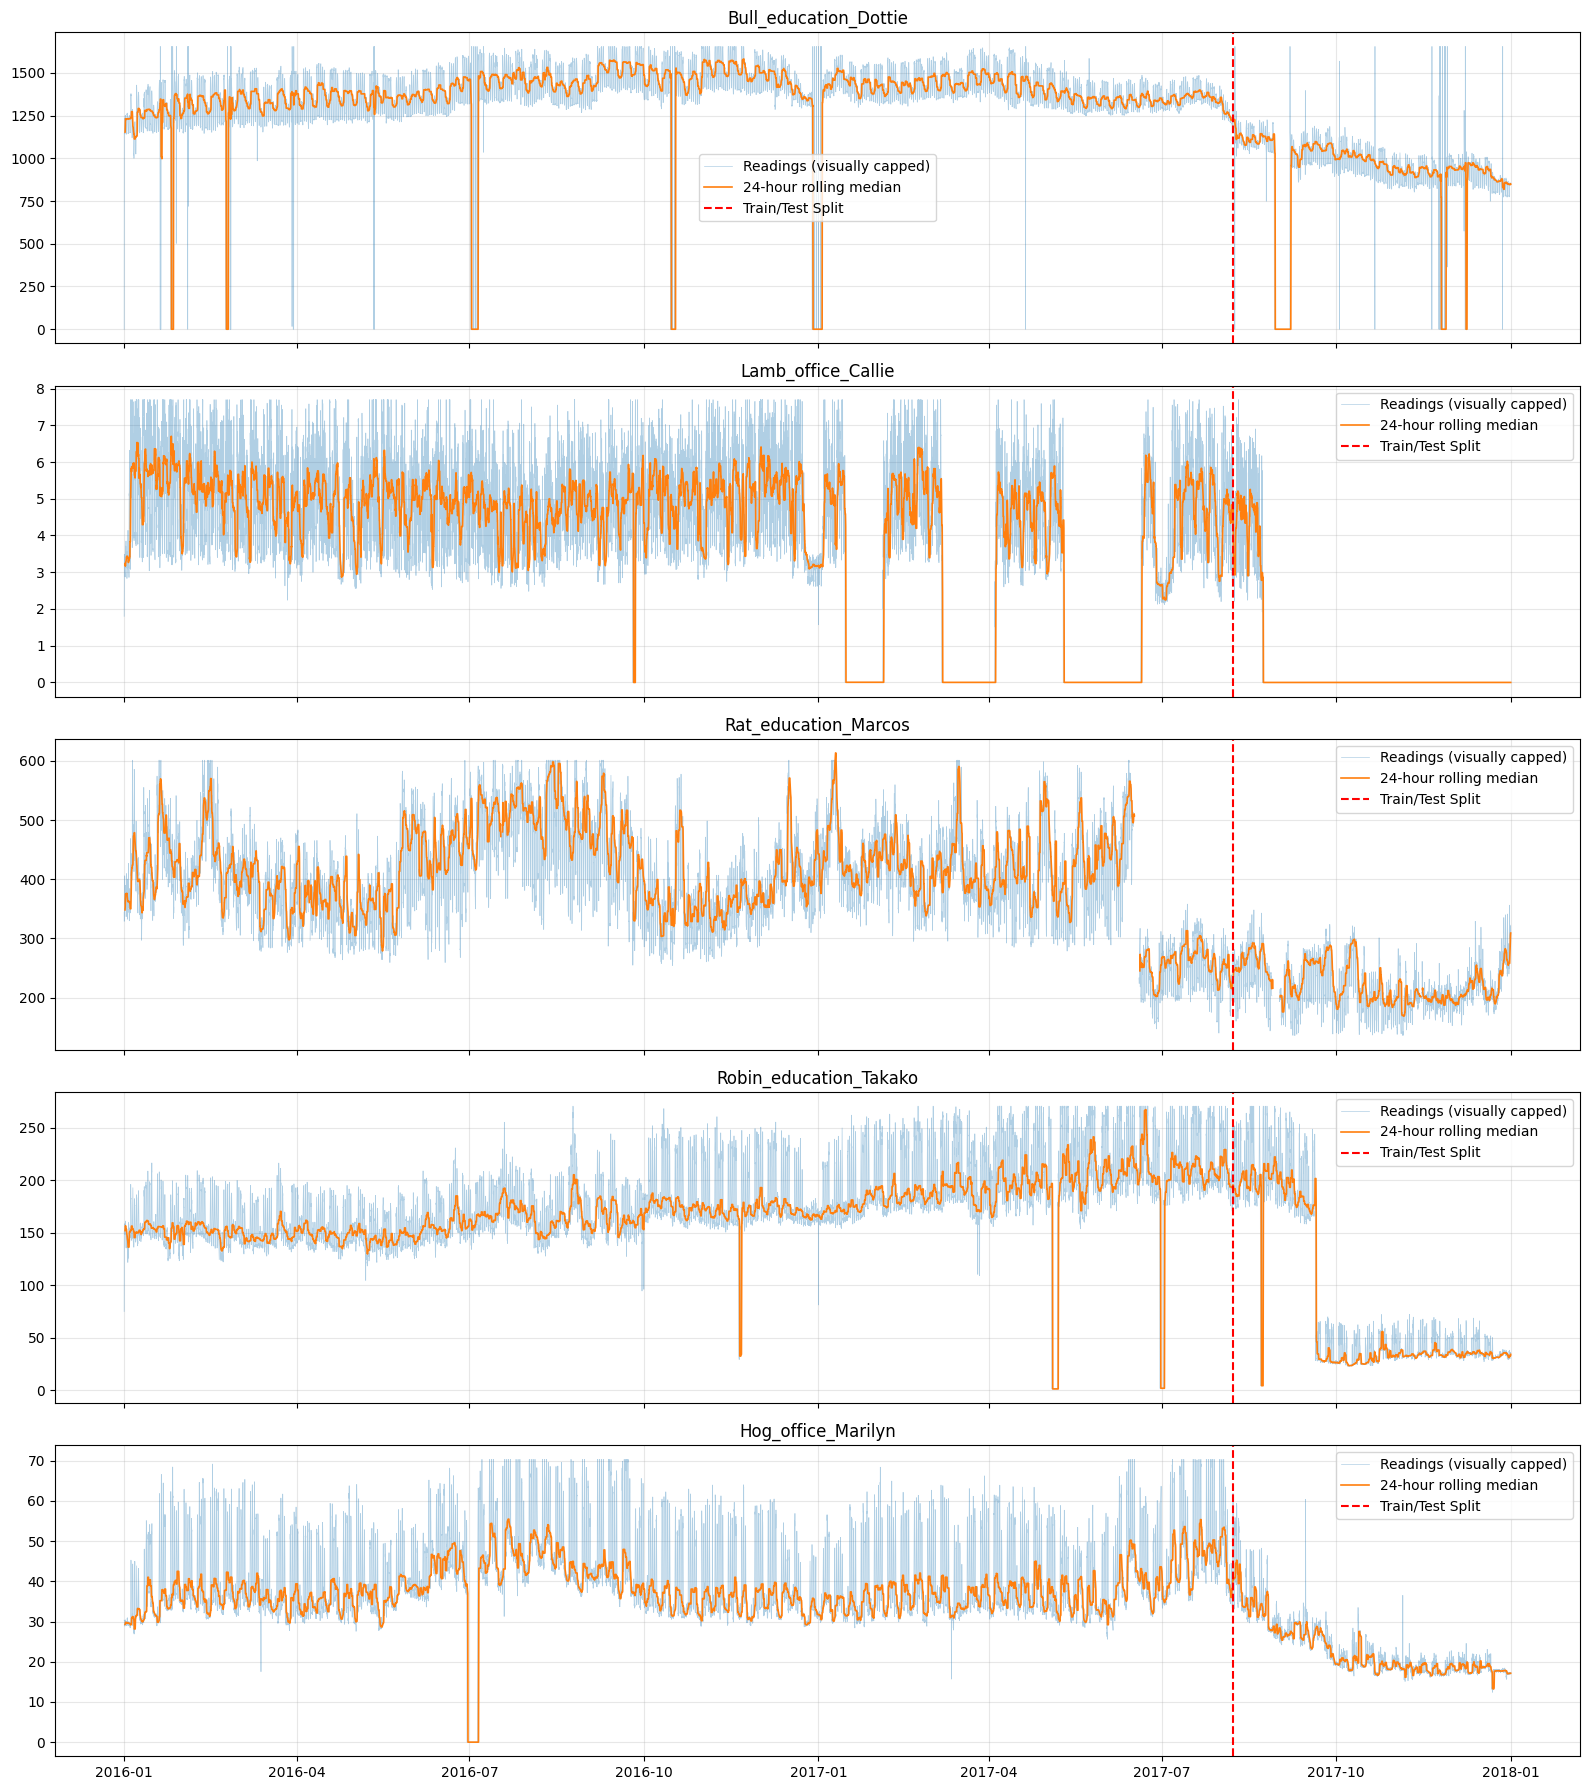

In [117]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 18),
    sharex=True
)

for ax, meter in zip(axes, diagnostic_meters):

    readings = model_data[meter]

    # Rolling median smooths short-term fluctuations
    rolling_median = readings.rolling(
        window=24,
        min_periods=12
    ).median()

    # Limit the display range to the 99th percentile
    upper_limit = readings.quantile(0.99)

    ax.plot(
        readings.index,
        readings.clip(upper=upper_limit),
        alpha=0.35,
        linewidth=0.5,
        label="Readings (visually capped)"
    )

    ax.plot(
        rolling_median.index,
        rolling_median,
        linewidth=1.2,
        label="24-hour rolling median"
    )

    ax.axvline(
        train_end,
        color="red",
        linestyle="--",
        label="Train/Test Split"
    )

    ax.set_title(meter)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [118]:
# Historical baseline for all usable meters
baseline = meter_stats.loc[valid_meters, ["median", "scale"]].copy()

print("Meters with baselines:", len(baseline))
display(baseline.head())

Meters with baselines: 1278


,median,scale
Panther_parking_Lorriane,10.2020,4.448690
Panther_lodging_Cora,124.1240,29.435244
Panther_office_Hannah,4.8529,4.813557
Panther_lodging_Hattie,134.8260,42.825791
Panther_education_Teofila,136.1763,60.549236


In [119]:
# Extract testing-period readings
test_readings = model_data.loc[test_start:, valid_meters].copy()

# Calculate the rolling 7-day median
rolling_7d = test_readings.rolling(
    window=168,
    min_periods=168
).median()

# Calculate robust deviation from historical baseline
change_scores = (
    rolling_7d.subtract(baseline["median"], axis=1)
    .divide(baseline["scale"], axis=1)
)

# Identify substantial persistent deviations
change_flags = change_scores.abs() > 3.5

print("Testing observations:", test_readings.shape)
print("Change-score shape:", change_scores.shape)

Testing observations: (3509, 1278)
Change-score shape: (3509, 1278)


In [120]:
change_summary = pd.DataFrame({
    "meter": change_flags.columns,
    "flagged_hours": change_flags.sum().values,
    "evaluated_hours": change_flags.notna().sum().values
})

change_summary["change_percentage"] = (
    change_summary["flagged_hours"]
    / change_summary["evaluated_hours"] * 100
)

change_summary = change_summary.sort_values(
    "change_percentage",
    ascending=False
)

display(change_summary.head(20).round(2))

,meter,flagged_hours,evaluated_hours,change_percentage
20,Panther_assembly_Pamella,3342,3509,95.24
1101,Hog_office_Rolando,3342,3509,95.24
693,Lamb_assembly_Alden,3342,3509,95.24
656,Lamb_education_Chet,3250,3509,92.62
665,Lamb_industrial_Willard,3202,3509,91.25
289,Rat_public_Nell,3086,3509,87.95
754,Lamb_industrial_Venessa,3083,3509,87.86
1189,Eagle_health_Gregoria,2958,3509,84.30
1062,Hog_other_Lynette,2948,3509,84.01
267,Fox_public_Belle,2876,3509,81.96


In [121]:
# Identify observations with a valid 7-day rolling score
valid_scores = change_scores.notna()

# Identify upward and downward changes
upward_flags = change_scores > 3.5
downward_flags = change_scores < -3.5

# Calculate corrected summary for all meters
change_summary = pd.DataFrame({
    "meter": change_scores.columns,

    "evaluated_hours": valid_scores.sum().values,

    "upward_changes": (
        upward_flags & valid_scores
    ).sum().values,

    "downward_changes": (
        downward_flags & valid_scores
    ).sum().values,

    "total_changes": (
        (upward_flags | downward_flags) & valid_scores
    ).sum().values
})

change_summary["change_percentage"] = (
    change_summary["total_changes"]
    / change_summary["evaluated_hours"] * 100
)

change_summary = change_summary.sort_values(
    "change_percentage",
    ascending=False
)

display(change_summary.head(20).round(2))

,meter,evaluated_hours,upward_changes,downward_changes,total_changes,change_percentage
20,Panther_assembly_Pamella,3342,3342,0,3342,100.00
1101,Hog_office_Rolando,3342,3342,0,3342,100.00
437,Rat_education_Francisca,2745,2745,0,2745,100.00
693,Lamb_assembly_Alden,3342,0,3342,3342,100.00
656,Lamb_education_Chet,3342,0,3250,3250,97.25
665,Lamb_industrial_Willard,3342,0,3202,3202,95.81
289,Rat_public_Nell,3342,3086,0,3086,92.34
754,Lamb_industrial_Venessa,3342,0,3083,3083,92.25
1189,Eagle_health_Gregoria,3342,0,2958,2958,88.51
1062,Hog_other_Lynette,3342,0,2948,2948,88.21


In [122]:
# Convert change scores into a long-format table
scores_long = (
    change_scores
    .rename_axis(index="timestamp", columns="meter")
    .stack()
    .rename("change_score")
    .reset_index()
)

# Identify direction and threshold crossings
scores_long["direction"] = "Normal"

scores_long.loc[
    scores_long["change_score"] > 3.5, "direction"
] = "Upward"

scores_long.loc[
    scores_long["change_score"] < -3.5, "direction"
] = "Downward"

# Keep only flagged observations
events = scores_long[
    scores_long["direction"] != "Normal"
].copy()

# Sort chronologically within each meter and direction
events = events.sort_values(
    ["meter", "direction", "timestamp"]
)

# Identify gaps between consecutive flagged hours
time_gap = (
    events.groupby(["meter", "direction"])["timestamp"]
    .diff()
)

# Start a new episode whenever the gap exceeds one hour
events["episode"] = (
    time_gap.ne(pd.Timedelta(hours=1))
    .groupby([events["meter"], events["direction"]])
    .cumsum()
)

# Summarize each continuous episode
episode_summary = (
    events.groupby(["meter", "direction", "episode"])
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        duration_hours=("timestamp", "size"),
        maximum_deviation=("change_score", "max"),
        minimum_deviation=("change_score", "min")
    )
    .reset_index()
)

# Retain episodes lasting at least 24 hours
persistent_episodes = episode_summary[
    episode_summary["duration_hours"] >= 24
].copy()

persistent_episodes = persistent_episodes.sort_values(
    "duration_hours",
    ascending=False
)

print("Total detected episodes:", len(episode_summary))
print("Episodes lasting at least 24 hours:", len(persistent_episodes))

display(persistent_episodes.head(20).round(2))

Total detected episodes: 194
Episodes lasting at least 24 hours: 166


,meter,direction,episode,start_time,end_time,duration_hours,maximum_deviation,minimum_deviation
122,Lamb_assembly_Alden,Downward,1,2017-08-14 18:00:00,2017-12-31 23:00:00,3342,-6.07,-6.07
111,Hog_office_Rolando,Upward,1,2017-08-14 18:00:00,2017-12-31 23:00:00,3342,5.65,4.95
143,Panther_assembly_Pamella,Upward,1,2017-08-14 18:00:00,2017-12-31 23:00:00,3342,66.93,11.61
129,Lamb_education_Chet,Downward,1,2017-08-18 14:00:00,2017-12-31 23:00:00,3250,-4.05,-4.05
135,Lamb_industrial_Willard,Downward,1,2017-08-20 14:00:00,2017-12-31 23:00:00,3202,-4.38,-4.38
134,Lamb_industrial_Venessa,Downward,1,2017-08-25 13:00:00,2017-12-31 23:00:00,3083,-3.80,-5.05
39,Eagle_health_Gregoria,Downward,1,2017-08-14 18:00:00,2017-12-15 23:00:00,2958,-4.88,-9.98
115,Hog_other_Lynette,Downward,1,2017-08-14 18:00:00,2017-12-15 13:00:00,2948,-3.54,-5.06
190,Robin_education_Takako,Downward,1,2017-09-23 12:00:00,2017-12-31 23:00:00,2388,-3.62,-4.97
67,Fox_public_Belle,Upward,2,2017-09-09 21:00:00,2017-12-16 17:00:00,2349,7.10,5.09


In [124]:
# Define the testing period boundaries
test_end = model_data.index.max()

print("Testing starts:", test_start)
print("Testing ends:", test_end)

Testing starts: 2017-08-07 19:00:00
Testing ends: 2017-12-31 23:00:00


In [125]:
# Include the last 167 training hours as rolling-window context
rolling_context = model_data.loc[
    :test_end, valid_meters
].tail(167)

# Add the complete testing period
rolling_input = pd.concat([
    rolling_context,
    test_readings
])

# Calculate the 7-day rolling median
rolling_7d_corrected = rolling_input.rolling(
    window=168,
    min_periods=168
).median()

# Keep only the testing period
rolling_7d_corrected = rolling_7d_corrected.loc[test_start:]

# Recalculate robust change scores
change_scores = (
    rolling_7d_corrected
    .subtract(baseline["median"], axis=1)
    .divide(baseline["scale"], axis=1)
)

print("Corrected testing shape:", change_scores.shape)
print("Missing change scores:", change_scores.isna().sum().sum())

Corrected testing shape: (3509, 1278)
Missing change scores: 63624


In [126]:
# Count missing change scores for each meter
missing_score_summary = pd.DataFrame({
    "meter": change_scores.columns,
    "missing_scores": change_scores.isna().sum().values,
    "valid_scores": change_scores.notna().sum().values
})

missing_score_summary["missing_percentage"] = (
    missing_score_summary["missing_scores"] / len(change_scores) * 100
)

missing_score_summary = missing_score_summary.sort_values(
    "missing_percentage",
    ascending=False
)

print("Total missing scores:", change_scores.isna().sum().sum())
print("Meters with missing scores:",
      (missing_score_summary["missing_scores"] > 0).sum())

display(missing_score_summary.head(20).round(2))

Total missing scores: 63624
Meters with missing scores: 173


,meter,missing_scores,valid_scores,missing_percentage
178,Fox_assembly_Jerrod,3360,149,95.75
1060,Hog_assembly_Letha,1685,1824,48.02
963,Bull_assembly_Daryl,1482,2027,42.23
615,Bear_assembly_Roxy,1432,2077,40.81
568,Bear_education_Arnold,1176,2333,33.51
593,Bear_assembly_Genia,1149,2360,32.74
591,Bear_education_Fannie,1104,2405,31.46
1097,Hog_office_Catharine,1053,2456,30.01
495,Rat_education_Vicky,935,2574,26.65
323,Rat_education_Alfred,903,2606,25.73


In [127]:
# Missing readings in the testing period
test_missing_summary = pd.DataFrame({
    "meter": test_readings.columns,
    "missing_readings": test_readings.isna().sum().values
})

test_missing_summary = test_missing_summary.sort_values(
    "missing_readings",
    ascending=False
)

display(test_missing_summary.head(20))

,meter,missing_readings
365,Rat_assembly_Teodoro,607
370,Rat_public_Fredrick,574
331,Rat_education_Leonardo,462
475,Rat_education_Milagros,431
501,Rat_assembly_Gerald,430
437,Rat_education_Francisca,430
467,Rat_education_Maricela,408
396,Rat_public_Kermit,407
477,Rat_education_Dreama,387
77,Panther_education_Genevieve,376


In [128]:
# Keep the 167 hours before the test period as rolling context
rolling_context = model_data.loc[:train_end, valid_meters].tail(167)

rolling_input = pd.concat([
    rolling_context,
    test_readings
])

# Strict version: requires all 168 readings
rolling_strict = rolling_input.rolling(
    window=168,
    min_periods=168
).median().loc[test_start:test_end]

# Improved version: requires at least 144 valid readings
rolling_flexible = rolling_input.rolling(
    window=168,
    min_periods=144
).median().loc[test_start:test_end]

# Compare missing scores
comparison = pd.DataFrame({
    "method": ["Strict (168 readings)", "Flexible (144 readings)"],
    "missing_scores": [
        rolling_strict.isna().sum().sum(),
        rolling_flexible.isna().sum().sum()
    ],
    "valid_scores": [
        rolling_strict.notna().sum().sum(),
        rolling_flexible.notna().sum().sum()
    ]
})

display(comparison)

,method,missing_scores,valid_scores
0,Strict (168 readings),63190,4421312
1,Flexible (144 readings),21077,4463425


In [129]:
# Use the flexible rolling median
rolling_7d_corrected = rolling_flexible

# Compare each meter's rolling median with its training baseline
change_scores = (
    rolling_7d_corrected
    .subtract(baseline["median"], axis=1)
    .divide(baseline["scale"], axis=1)
)

print("Corrected testing shape:", change_scores.shape)
print("Missing change scores:", change_scores.isna().sum().sum())
print("Valid change scores:", change_scores.notna().sum().sum())

Corrected testing shape: (3509, 1278)
Missing change scores: 21077
Valid change scores: 4463425


In [130]:
# Identify upward and downward deviations
upward_flags = change_scores > 3.5
downward_flags = change_scores < -3.5

# Exclude missing scores from the evaluation
valid_scores = change_scores.notna()

# Summarize persistent changes for every meter
change_summary = pd.DataFrame({
    "meter": change_scores.columns,
    "evaluated_hours": valid_scores.sum().values,
    "upward_changes": (upward_flags & valid_scores).sum().values,
    "downward_changes": (downward_flags & valid_scores).sum().values,
    "total_changes": (
        (upward_flags | downward_flags) & valid_scores
    ).sum().values
})

change_summary["change_percentage"] = (
    change_summary["total_changes"] /
    change_summary["evaluated_hours"] * 100
)

change_summary = change_summary.sort_values(
    "change_percentage", ascending=False
)

display(change_summary.head(20).round(2))

,meter,evaluated_hours,upward_changes,downward_changes,total_changes,change_percentage
20,Panther_assembly_Pamella,3509,3509,0,3509,100.00
1101,Hog_office_Rolando,3509,3509,0,3509,100.00
437,Rat_education_Francisca,2960,2960,0,2960,100.00
693,Lamb_assembly_Alden,3509,0,3509,3509,100.00
289,Rat_public_Nell,3509,3253,0,3253,92.70
656,Lamb_education_Chet,3509,0,3250,3250,92.62
665,Lamb_industrial_Willard,3509,0,3202,3202,91.25
1062,Hog_other_Lynette,3509,0,3115,3115,88.77
754,Lamb_industrial_Venessa,3509,0,3083,3083,87.86
1189,Eagle_health_Gregoria,3509,0,3077,3077,87.69


In [131]:
import numpy as np
import pandas as pd

# Convert the score matrix into a long-format table
scores_long = (
    change_scores
    .rename_axis(index="timestamp", columns="meter")
    .stack()
    .rename("change_score")
    .reset_index()
)

# Classify each observation
scores_long["direction"] = np.select(
    [
        scores_long["change_score"] > 3.5,
        scores_long["change_score"] < -3.5
    ],
    ["Upward", "Downward"],
    default="Normal"
)

# Keep only observations showing significant changes
events = scores_long[
    scores_long["direction"] != "Normal"
].copy()

# Sort observations chronologically for each meter
events = events.sort_values(["meter", "timestamp"])

# Identify gaps and changes in direction
time_gap = events.groupby("meter")["timestamp"].diff()
previous_direction = events.groupby("meter")["direction"].shift()

# Start a new episode when:
# 1. There is a gap in hourly observations, or
# 2. The direction changes
new_episode = (
    time_gap.ne(pd.Timedelta(hours=1)) |
    events["direction"].ne(previous_direction)
)

events["episode"] = (
    new_episode.groupby(events["meter"]).cumsum()
)

# Summarize each continuous episode
episode_summary = (
    events.groupby(["meter", "episode", "direction"])
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        duration_hours=("timestamp", "size"),
        maximum_score=("change_score", "max"),
        minimum_score=("change_score", "min")
    )
    .reset_index()
)

# Retain episodes lasting at least 24 hours
persistent_episodes = episode_summary[
    episode_summary["duration_hours"] >= 24
].copy()

# Display the longest episodes
persistent_episodes = persistent_episodes.sort_values(
    "duration_hours", ascending=False
)

display(persistent_episodes.head(25).round(2))


,meter,episode,direction,start_time,end_time,duration_hours,maximum_score,minimum_score
153,Panther_assembly_Pamella,1,Upward,2017-08-07 19:00:00,2017-12-31 23:00:00,3509,66.93,11.61
132,Lamb_assembly_Alden,1,Downward,2017-08-07 19:00:00,2017-12-31 23:00:00,3509,-6.07,-6.07
120,Hog_office_Rolando,1,Upward,2017-08-07 19:00:00,2017-12-31 23:00:00,3509,5.65,4.95
139,Lamb_education_Chet,1,Downward,2017-08-18 14:00:00,2017-12-31 23:00:00,3250,-4.05,-4.05
145,Lamb_industrial_Willard,1,Downward,2017-08-20 14:00:00,2017-12-31 23:00:00,3202,-4.38,-4.38
124,Hog_other_Lynette,1,Downward,2017-08-07 19:00:00,2017-12-15 13:00:00,3115,-3.54,-5.40
144,Lamb_industrial_Venessa,1,Downward,2017-08-25 13:00:00,2017-12-31 23:00:00,3083,-3.80,-5.05
43,Eagle_health_Gregoria,1,Downward,2017-08-09 19:00:00,2017-12-15 23:00:00,3077,-4.88,-9.98
201,Robin_education_Takako,1,Downward,2017-09-23 12:00:00,2017-12-31 23:00:00,2388,-3.62,-4.97
72,Fox_public_Belle,2,Upward,2017-09-09 21:00:00,2017-12-16 17:00:00,2349,7.10,5.09


In [132]:
# Select representative meters
selected_meters = [
    "Panther_assembly_Pamella",
    "Lamb_assembly_Alden",
    "Hog_office_Rolando",
    "Robin_education_Takako",
    "Lamb_office_Bertha"
]

# Separate historical and testing readings
training_selected = model_data.loc[:train_end, selected_meters]
testing_selected = model_data.loc[test_start:, selected_meters]

# Compare actual reading statistics
comparison = pd.concat({
    "Training": training_selected.agg(["mean", "median", "std", "min", "max"]),
    "Testing": testing_selected.agg(["mean", "median", "std", "min", "max"])
}, axis=1)

display(comparison.round(2))

Training                                         \
       Panther_assembly_Pamella Lamb_assembly_Alden Hog_office_Rolando   
mean                      40.56                1.54             282.19   
median                     2.52                1.80             135.00   
std                       60.89                1.17             172.96   
min                        0.00                0.00               0.00   
max                      331.06               14.10             853.00   

                                                                  Testing  \
       Robin_education_Takako Lamb_office_Bertha Panther_assembly_Pamella   
mean                   178.51              44.46                   173.30   
median                 173.60               0.21                   178.83   
std                     37.50              57.89                    71.57   
min                      1.20               0.01                     1.40   
max                    316.90             341.10                   350.47   

                                                                      \
       Lamb_assembly_Alden Hog_office_Rolando Robin_education_Takako   
mean                   0.0             420.47                  84.29   
median                 0.0             415.00                  37.30   
std                    0.0              27.03                  77.81   
min                    0.0             373.00                   4.26   
max                    0.0             807.00                 289.00   

                           
       Lamb_office_Bertha  
mean                68.53  
median              63.50  
std                 53.12  
min                  0.03  
max                203.66

In [133]:
# Monthly average electricity readings for selected meters
monthly_readings = (
    model_data[selected_meters]
    .resample("MS")
    .mean()
)

display(monthly_readings.round(2))

,Panther_assembly_Pamella,Lamb_assembly_Alden,Hog_office_Rolando,Robin_education_Takako,Lamb_office_Bertha
timestamp,,,,,
2016-01-01,0.00,3.32,109.22,156.62,101.74
2016-02-01,0.00,2.72,113.70,158.58,94.37
2016-03-01,0.00,2.10,114.22,153.75,74.79
2016-04-01,0.00,2.00,114.45,154.20,85.14
2016-05-01,7.18,1.89,113.60,149.11,30.73
2016-06-01,42.02,1.89,118.61,160.97,0.03
2016-07-01,34.88,1.88,119.26,174.05,67.15
2016-08-01,32.42,1.70,116.62,168.01,101.98
2016-09-01,31.55,2.19,115.00,168.14,19.09


In [134]:
# Calculate monthly mean and median for all five meters
monthly_analysis = model_data[selected_meters].resample("MS").agg(
    ["mean", "median", "std"]
)

# Display the monthly statistics
display(monthly_analysis.round(2))

Panther_assembly_Pamella                Lamb_assembly_Alden         \
                               mean  median    std                mean median   
timestamp                                                                       
2016-01-01                     0.00    0.00   0.00                3.32    2.4   
2016-02-01                     0.00    0.00   0.00                2.72    2.0   
2016-03-01                     0.00    0.00   0.00                2.10    1.9   
2016-04-01                     0.00    0.00   0.00                2.00    2.0   
2016-05-01                     7.18    0.00  20.66                1.89    1.9   
2016-06-01                    42.02    2.52  52.84                1.89    1.9   
2016-07-01                    34.88    8.22  40.00                1.88    2.0   
2016-08-01                    32.42   21.66  32.95                1.70    1.6   
2016-09-01                    31.55   17.04  32.59                2.19    2.2   
2016-10-01                    29.34    2.64  31.88                1.93    1.9   
2016-11-01                   123.50  117.58  44.24                1.83    1.8   
2016-12-01                    78.20   30.41  83.08                1.89    1.9   
2017-01-01                    31.38   25.50  27.46                0.78    0.0   
2017-02-01                    38.88   56.61  25.26                1.66    1.8   
2017-03-01                    25.73   19.40  23.39                0.31    0.0   
2017-04-01                    25.06   20.40  19.92                1.21    1.4   
2017-05-01                    15.88    2.00  20.36                0.43    0.0   
2017-06-01                    38.95   34.01  40.67                0.00    0.0   
2017-07-01                   176.16  183.44  81.63                0.00    0.0   
2017-08-01                   215.56  199.34  51.07                0.00    0.0   
2017-09-01                   199.65  231.74  82.18                0.00    0.0   
2017-10-01                   199.15  203.54  44.13                0.00    0.0   
2017-11-01                   166.19  165.03  46.07                0.00    0.0   
2017-12-01                    94.70   60.81  50.57                0.00    0.0   

                 Hog_office_Rolando                Robin_education_Takako  \
             std               mean median     std                   mean   
timestamp                                                                   
2016-01-01  2.26             109.22  105.0    9.59                 156.62   
2016-02-01  1.51             113.70  110.0   10.22                 158.58   
2016-03-01  1.01             114.22  111.0   10.83                 153.75   
2016-04-01  0.13             114.45  112.0    9.85                 154.20   
2016-05-01  0.14             113.60  110.0    8.81                 149.11   
2016-06-01  0.11             118.61  115.0   11.62                 160.97   
2016-07-01  0.36             119.26  116.0    9.05                 174.05   
2016-08-01  0.31             116.62  113.5    8.82                 168.01   
2016-09-01  0.60             115.00  111.0    8.75                 168.14   
2016-10-01  0.09             185.17  113.0  143.97                 184.92   
2016-11-01  0.11             469.41  457.0   36.55                 176.96   
2016-12-01  0.10             460.34  452.0   31.98                 180.10   
2017-01-01  0.92             460.09  449.0   33.20                 184.75   
2017-02-01  0.58             466.58  452.0   35.33                 195.84   
2017-03-01  0.64             468.94  457.0   36.37                 198.84   
2017-04-01  0.48             456.89  446.0   33.53                 207.22   
2017-05-01  0.73             454.45  446.0   28.90                 191.05   
2017-06-01  0.00             450.88  445.5   32.52                 211.86   
2017-07-01  0.00             432.93  426.0   28.44                 209.77   
2017-08-01  0.00             410.58  402.0   25.34                 204.79   
2017-09-01  0.00             415.15  404.5   28.64  

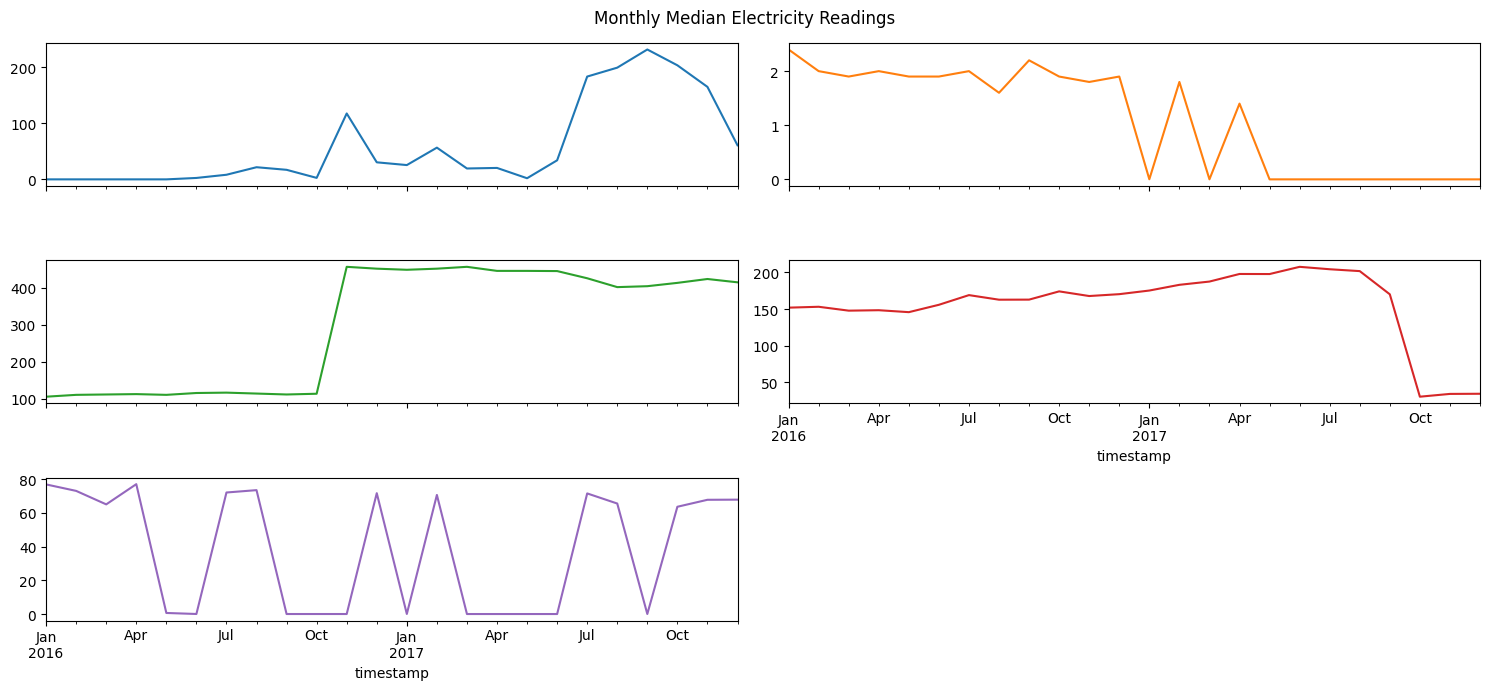

In [135]:
import matplotlib.pyplot as plt

# Monthly median consumption
monthly_median = model_data[selected_meters].resample("MS").median()

monthly_median.plot(
    figsize=(15, 7),
    subplots=True,
    layout=(3, 2),
    sharex=True,
    legend=False,
    title="Monthly Median Electricity Readings"
)

plt.tight_layout()
plt.show()

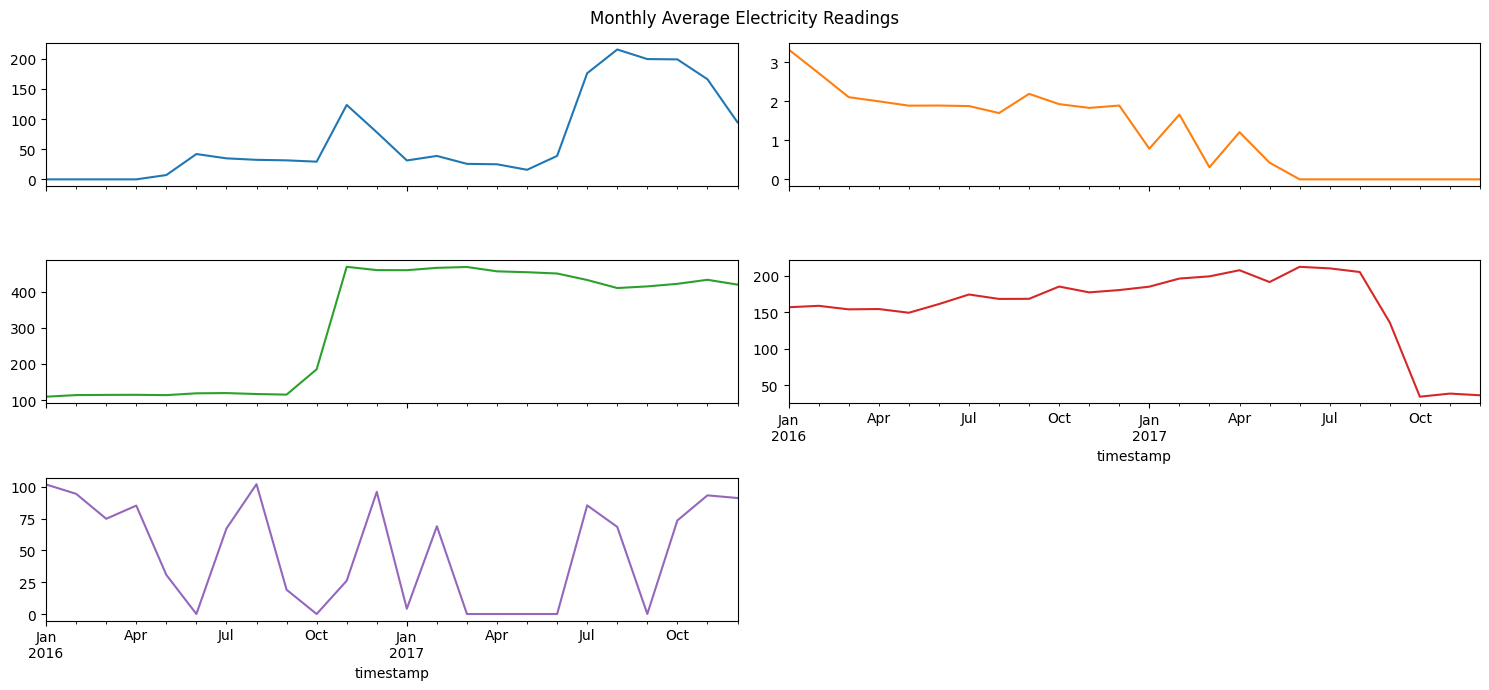

In [136]:
# Monthly average consumption
monthly_mean = model_data[selected_meters].resample("MS").mean()

monthly_mean.plot(
    figsize=(15, 7),
    subplots=True,
    layout=(3, 2),
    sharex=True,
    legend=False,
    title="Monthly Average Electricity Readings"
)

plt.tight_layout()
plt.show()

In [137]:
# Select a balanced training sample
comparison_train = (
    train_model_data
    .groupby("meter", group_keys=False)
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

# Collect a balanced test sample from the saved Parquet batches
comparison_test_parts = []

for file in test_files:
    batch = pd.read_parquet(file)

    batch = batch[
        batch["meter"].isin(valid_meters)
    ]

    sampled = (
        batch.groupby("meter", group_keys=False)
        .sample(n=10, random_state=42)
    )

    comparison_test_parts.append(sampled)

comparison_test = pd.concat(
    comparison_test_parts,
    ignore_index=True
)

# Extract the common model features
X_train_compare = comparison_train[feature_columns].copy()
X_test_compare = comparison_test[feature_columns].copy()

print("Training shape:", X_train_compare.shape)
print("Testing shape:", X_test_compare.shape)
print("Training meters:", comparison_train["meter"].nunique())
print("Testing meters:", comparison_test["meter"].nunique())

print("Training missing values:", X_train_compare.isna().sum().sum())
print("Testing missing values:", X_test_compare.isna().sum().sum())

KeyError: "None of [Index(['reading_z', 'lag_1_z', 'lag_24_z', 'lag_168_z', 'rolling_mean_24_z',\n       'rolling_std_ratio', 'deviation_24_z', 'hour_sin', 'hour_cos',\n       'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend'],\n      dtype='object')] are in the [columns]"

In [138]:
print("TRAINING DATA COLUMNS:")
print(comparison_train.columns.tolist())

print("\nTESTING DATA COLUMNS:")
print(comparison_test.columns.tolist())

print("\nTEST FILE COLUMNS:")
sample_test_file = pd.read_parquet(test_files[0])
print(sample_test_file.columns.tolist())

TRAINING DATA COLUMNS:
['meter', 'timestamp', 'reading_z', 'lag_1_z', 'lag_24_z', 'lag_168_z', 'rolling_mean_24_z', 'rolling_std_ratio', 'deviation_24_z', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend', 'anomaly_prediction', 'anomaly_score', 'is_anomaly']

TESTING DATA COLUMNS:
['timestamp', 'meter', 'reading', 'was_missing_original', 'anomaly_prediction', 'anomaly_score', 'is_anomaly']

TEST FILE COLUMNS:
['timestamp', 'meter', 'reading', 'was_missing_original', 'anomaly_prediction', 'anomaly_score', 'is_anomaly']


In [139]:
import pandas as pd
import numpy as np
import glob
import os

# Read the original engineered feature files
feature_files = sorted(
    glob.glob("/content/drive/MyDrive/energy_anomaly_features/*.parquet")
)

comparison_test_parts = []

for file in feature_files:

    batch = pd.read_parquet(file)

    # Keep only testing-period observations
    batch = batch[
        (batch["timestamp"] >= test_start) &
        (batch["meter"].isin(valid_meters)) &
        (batch["was_missing_original"] == 0)
    ].copy()

    if batch.empty:
        continue

    # Apply training-period normalization
    batch["training_mean"] = batch["meter"].map(mean_map)
    batch["training_scale"] = batch["meter"].map(scale_map)

    batch["reading_z"] = (
        batch["reading"] - batch["training_mean"]
    ) / batch["training_scale"]

    batch["lag_1_z"] = (
        batch["lag_1"] - batch["training_mean"]
    ) / batch["training_scale"]

    batch["lag_24_z"] = (
        batch["lag_24"] - batch["training_mean"]
    ) / batch["training_scale"]

    batch["lag_168_z"] = (
        batch["lag_168"] - batch["training_mean"]
    ) / batch["training_scale"]

    batch["rolling_mean_24_z"] = (
        batch["rolling_mean_24"] - batch["training_mean"]
    ) / batch["training_scale"]

    batch["rolling_std_ratio"] = (
        batch["rolling_std_24"] / batch["training_scale"]
    )

    batch["deviation_24_z"] = (
        batch["deviation_24"] / batch["training_scale"]
    )

    # Convert time features into cyclical features
    batch["hour_sin"] = np.sin(2 * np.pi * batch["hour"] / 24)
    batch["hour_cos"] = np.cos(2 * np.pi * batch["hour"] / 24)

    batch["dow_sin"] = np.sin(2 * np.pi * batch["day_of_week"] / 7)
    batch["dow_cos"] = np.cos(2 * np.pi * batch["day_of_week"] / 7)

    batch["month_sin"] = np.sin(
        2 * np.pi * (batch["month"] - 1) / 12
    )
    batch["month_cos"] = np.cos(
        2 * np.pi * (batch["month"] - 1) / 12
    )

    # Select the common model features
    batch = batch.dropna(subset=feature_columns)

    # Keep a balanced sample from each meter
    sampled = (
        batch.groupby("meter", group_keys=False)
        .sample(n=10, random_state=42)
    )

    comparison_test_parts.append(sampled)

# Combine all batches
comparison_test = pd.concat(
    comparison_test_parts,
    ignore_index=True
)

# Prepare testing features
X_test_compare = comparison_test[feature_columns].copy()

print("Testing dataset shape:", comparison_test.shape)
print("Testing feature shape:", X_test_compare.shape)
print("Number of meters:", comparison_test["meter"].nunique())
print("Missing values:", X_test_compare.isna().sum().sum())
print("Infinite values:", np.isinf(X_test_compare).sum().sum())

Testing dataset shape: (12780, 29)
Testing feature shape: (12780, 14)
Number of meters: 1278
Missing values: 0
Infinite values: 0


In [140]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
import numpy as np
import time

models = {
    "Isolation Forest": IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    ),

    "LOF": LocalOutlierFactor(
        n_neighbors=35,
        contamination=0.05,
        novelty=True,
        n_jobs=-1
    ),

    "Robust Covariance": EllipticEnvelope(
        contamination=0.05,
        random_state=42,
        support_fraction=0.8
    )
}

model_results = {}

for model_name, model in models.items():

    start = time.time()

    model.fit(X_train_compare)

    predictions = model.predict(X_test_compare)
    scores = model.decision_function(X_test_compare)

    model_results[model_name] = {
        "predictions": predictions,
        "scores": scores,
        "training_time_seconds": round(time.time() - start, 2)
    }

    anomaly_rate = (predictions == -1).mean() * 100

    print(f"\n{model_name}")
    print("Anomaly rate:", round(anomaly_rate, 2), "%")
    print("Execution time:",
          model_results[model_name]["training_time_seconds"], "seconds")


Isolation Forest
Anomaly rate: 6.6 %
Execution time: 2.15 seconds


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(



LOF
Anomaly rate: 32.14 %
Execution time: 12.23 seconds

Robust Covariance
Anomaly rate: 3.83 %
Execution time: 5.71 seconds


In [141]:
# Collect predictions from all three models
prediction_matrix = np.column_stack([
    model_results["Isolation Forest"]["predictions"],
    model_results["LOF"]["predictions"],
    model_results["Robust Covariance"]["predictions"]
])

# Count anomaly votes (-1 means anomaly)
anomaly_votes = (prediction_matrix == -1).sum(axis=1)

# Majority voting: at least 2 votes
ensemble_predictions = np.where(anomaly_votes >= 2, -1, 1)

# Store results
comparison_test["anomaly_votes"] = anomaly_votes
comparison_test["ensemble_prediction"] = ensemble_predictions
comparison_test["ensemble_is_anomaly"] = (
    ensemble_predictions == -1
).astype(int)

# Display results
print("Ensemble anomaly count:",
      comparison_test["ensemble_is_anomaly"].sum())

print("Ensemble anomaly rate:",
      round(comparison_test["ensemble_is_anomaly"].mean() * 100, 2), "%")

print("\nVote distribution:")
print(comparison_test["anomaly_votes"].value_counts().sort_index())

Ensemble anomaly count: 829
Ensemble anomaly rate: 6.49 %

Vote distribution:
anomaly_votes
0    8444
1    3507
2     554
3     275
Name: count, dtype: int64


In [142]:
# Calculate anomaly rate for each meter
meter_ensemble_summary = (
    comparison_test.groupby("meter")
    .agg(
        total_observations=("ensemble_is_anomaly", "count"),
        anomaly_count=("ensemble_is_anomaly", "sum"),
        anomaly_rate=("ensemble_is_anomaly", "mean")
    )
    .reset_index()
)

meter_ensemble_summary["anomaly_rate"] *= 100

# Sort by highest anomaly rate
meter_ensemble_summary = meter_ensemble_summary.sort_values(
    "anomaly_rate", ascending=False
)

display(meter_ensemble_summary.head(15))

,meter,total_observations,anomaly_count,anomaly_rate
721,Lamb_education_Sylvester,10,10,100.0
707,Lamb_education_Phil,10,10,100.0
717,Lamb_education_Salvador,10,10,100.0
699,Lamb_education_Marty,10,10,100.0
685,Lamb_education_Kasha,10,10,100.0
659,Lamb_education_Dolly,10,10,100.0
703,Lamb_education_Nathan,10,10,100.0
785,Panther_assembly_Pamella,10,10,100.0
55,Bear_education_Santos,10,10,100.0
755,Lamb_public_Angeline,10,10,100.0


In [143]:
# Inspect voting patterns for the 100% anomaly-rate meters
top_meters = meter_ensemble_summary.head(15)["meter"].tolist()

top_meter_votes = comparison_test[
    comparison_test["meter"].isin(top_meters)
].groupby("meter").agg(
    observations=("anomaly_votes", "count"),
    zero_votes=("anomaly_votes", lambda x: (x == 0).sum()),
    one_vote=("anomaly_votes", lambda x: (x == 1).sum()),
    two_votes=("anomaly_votes", lambda x: (x == 2).sum()),
    three_votes=("anomaly_votes", lambda x: (x == 3).sum())
).reset_index()

display(top_meter_votes)

,meter,observations,zero_votes,one_vote,two_votes,three_votes
0,Bear_education_Santos,10,0,0,0,10
1,Lamb_education_Dolly,10,0,0,6,4
2,Lamb_education_Kasha,10,0,0,10,0
3,Lamb_education_Marty,10,0,0,10,0
4,Lamb_education_Nathan,10,0,0,10,0
5,Lamb_education_Phil,10,0,0,10,0
6,Lamb_education_Salvador,10,0,0,6,4
7,Lamb_education_Sylvester,10,0,0,4,6
8,Lamb_education_Wilbert,10,0,0,10,0
9,Lamb_industrial_Venessa,10,0,0,10,0


In [144]:
import glob
import pandas as pd

feature_files = sorted(
    glob.glob("/content/drive/MyDrive/energy_anomaly_features/*.parquet")
)

print("Number of feature files:", len(feature_files))
print("Number of test result files:", len(test_files))
print("Comparison test observations:", len(comparison_test))
print("Full test observations:", sum(len(pd.read_parquet(f)) for f in feature_files))

Number of feature files: 26
Number of test result files: 26
Comparison test observations: 12780
Full test observations: 22456320


In [145]:
import os
import glob
import pandas as pd
import numpy as np

output_folder = "/content/drive/MyDrive/energy_anomaly_full_ensemble"
os.makedirs(output_folder, exist_ok=True)

full_test_results = []

for i, file in enumerate(feature_files, start=1):

    batch = pd.read_parquet(file)

    # Keep only test-period observations and valid meters
    batch = batch[
        (batch["timestamp"] >= test_start) &
        (batch["timestamp"] <= test_end) &
        (batch["meter"].isin(valid_meters)) &
        (batch["was_missing_original"] == 0)
    ].copy()

    # Apply training-based normalization
    batch["reading_z"] = (
        batch["reading"] - batch["meter"].map(mean_map)
    ) / batch["meter"].map(scale_map)

    for col in ["lag_1", "lag_24", "lag_168",
                "rolling_mean_24", "deviation_24"]:
        batch[col + "_z"] = (
            batch[col] - batch["meter"].map(mean_map)
        ) / batch["meter"].map(scale_map)

    batch["rolling_std_ratio"] = (
        batch["rolling_std_24"] /
        batch["meter"].map(scale_map)
    )

    # Cyclical time features
    batch["hour_sin"] = np.sin(2 * np.pi * batch["timestamp"].dt.hour / 24)
    batch["hour_cos"] = np.cos(2 * np.pi * batch["timestamp"].dt.hour / 24)

    batch["dow_sin"] = np.sin(
        2 * np.pi * batch["timestamp"].dt.dayofweek / 7
    )
    batch["dow_cos"] = np.cos(
        2 * np.pi * batch["timestamp"].dt.dayofweek / 7
    )

    batch["month_sin"] = np.sin(
        2 * np.pi * (batch["timestamp"].dt.month - 1) / 12
    )
    batch["month_cos"] = np.cos(
        2 * np.pi * (batch["timestamp"].dt.month - 1) / 12
    )

    batch["is_weekend"] = (
        batch["timestamp"].dt.dayofweek >= 5
    ).astype(int)

    batch = batch.dropna(subset=feature_columns)

    if batch.empty:
        continue

    X_batch = batch[feature_columns].copy()

    # Predict with all three fitted models
    batch["if_prediction"] = models["Isolation Forest"].predict(X_batch)
    batch["lof_prediction"] = models["LOF"].predict(X_batch)
    batch["rc_prediction"] = models["Robust Covariance"].predict(X_batch)

    # Majority voting
    votes = (
        (batch[["if_prediction", "lof_prediction", "rc_prediction"]] == -1)
        .sum(axis=1)
    )

    batch["anomaly_votes"] = votes
    batch["ensemble_prediction"] = np.where(votes >= 2, -1, 1)
    batch["ensemble_is_anomaly"] = (
        batch["ensemble_prediction"] == -1
    ).astype(int)

    # Save each batch
    result = batch[[
        "timestamp", "meter", "reading",
        "if_prediction", "lof_prediction", "rc_prediction",
        "anomaly_votes", "ensemble_prediction",
        "ensemble_is_anomaly"
    ]].copy()

    result_path = os.path.join(
        output_folder, f"ensemble_batch_{i:02d}.parquet"
    )

    result.to_parquet(result_path, index=False)
    full_test_results.append(result)

    print(f"Completed batch {i}/{len(feature_files)}: {len(result):,} rows")

# Combine all test predictions
full_ensemble_results = pd.concat(
    full_test_results, ignore_index=True
)

print("\nFull-test ensemble completed.")
print("Total observations:", len(full_ensemble_results))
print(
    "Ensemble anomaly rate:",
    round(full_ensemble_results["ensemble_is_anomaly"].mean() * 100, 2),
    "%"
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Completed batch 1/26: 175,381 rows


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Completed batch 2/26: 173,882 rows


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Completed batch 3/26: 175,448 rows


... (42 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Completed batch 25/26: 175,429 rows


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Completed batch 26/26: 105,266 rows

Full-test ensemble completed.
Total observations: 4452047
Ensemble anomaly rate: 3.8 %


In [146]:
# Individual model anomaly rates
model_columns = {
    "Isolation Forest": "if_prediction",
    "LOF": "lof_prediction",
    "Robust Covariance": "rc_prediction",
    "Majority Voting Ensemble": "ensemble_prediction"
}

comparison_summary = []

for model_name, column in model_columns.items():
    anomaly_count = (full_ensemble_results[column] == -1).sum()

    comparison_summary.append({
        "Model": model_name,
        "Anomaly Count": anomaly_count,
        "Anomaly Rate (%)": round(
            anomaly_count / len(full_ensemble_results) * 100, 2
        )
    })

comparison_summary = pd.DataFrame(comparison_summary)
display(comparison_summary)

# Full-test voting distribution
print("\nFull-test vote distribution:")
display(
    full_ensemble_results["anomaly_votes"]
    .value_counts()
    .sort_index()
    .rename_axis("Anomaly Votes")
    .to_frame("Observations")
)

,Model,Anomaly Count,Anomaly Rate (%)
0,Isolation Forest,287895,6.47
1,LOF,221522,4.98
2,Robust Covariance,190468,4.28
3,Majority Voting Ensemble,168957,3.80



Full-test vote distribution:


,Observations
Anomaly Votes,
0,4000994
1,282096
2,89082
3,79875


In [147]:
full_meter_summary = (
    full_ensemble_results.groupby("meter")
    .agg(
        total_observations=("ensemble_is_anomaly", "count"),
        anomaly_count=("ensemble_is_anomaly", "sum"),
        anomaly_rate=("ensemble_is_anomaly", "mean")
    )
    .reset_index()
)

full_meter_summary["anomaly_rate"] *= 100

full_meter_summary = full_meter_summary.sort_values(
    "anomaly_rate", ascending=False
)

display(full_meter_summary.head(20))

,meter,total_observations,anomaly_count,anomaly_rate
727,Lamb_education_Willetta,3509,3509,100.000000
737,Lamb_office_Bertha,3509,3509,100.000000
755,Lamb_public_Angeline,3509,3509,100.000000
55,Bear_education_Santos,3416,3416,100.000000
556,Hog_office_Lavon,3509,3509,100.000000
645,Lamb_assembly_Zita,3509,3509,100.000000
785,Panther_assembly_Pamella,3509,3369,96.010259
639,Lamb_assembly_Rosa,3509,3269,93.160445
244,Eagle_health_Gregoria,3509,3209,91.450556
31,Bear_education_Irene,3414,2997,87.785589


In [148]:
import pandas as pd
import numpy as np

selected_meters = [
    "Panther_assembly_Pamella",
    "Lamb_assembly_Alden",
    "Hog_office_Rolando",
    "Robin_education_Takako",
    "Lamb_office_Bertha"
]

# Ensemble results for the selected meters
ensemble_validation = (
    full_ensemble_results[
        full_ensemble_results["meter"].isin(selected_meters)
    ]
    .groupby("meter")
    .agg(
        scored_observations=("ensemble_is_anomaly", "count"),
        ensemble_anomalies=("ensemble_is_anomaly", "sum"),
        ensemble_anomaly_rate=("ensemble_is_anomaly", "mean")
    )
)

ensemble_validation["ensemble_anomaly_rate"] *= 100

# Persistent change detection results
change_validation = []

for meter in selected_meters:
    scores = change_scores[meter].dropna()

    change_validation.append({
        "meter": meter,
        "valid_change_scores": len(scores),
        "upward_change_rate": (scores > 3.5).mean() * 100,
        "downward_change_rate": (scores < -3.5).mean() * 100
    })

change_validation = pd.DataFrame(
    change_validation
).set_index("meter")

# Combine both analyses
validation_summary = ensemble_validation.join(
    change_validation,
    how="outer"
)

display(validation_summary.round(2))

,scored_observations,ensemble_anomalies,ensemble_anomaly_rate,valid_change_scores,upward_change_rate,downward_change_rate
meter,,,,,,
Hog_office_Rolando,3509,4,0.11,3509,100.00,0.00
Lamb_assembly_Alden,3509,0,0.00,3509,0.00,100.00
Lamb_office_Bertha,3509,3509,100.00,3509,72.24,0.00
Panther_assembly_Pamella,3509,3369,96.01,3509,100.00,0.00
Robin_education_Takako,3509,122,3.48,3509,0.00,68.05


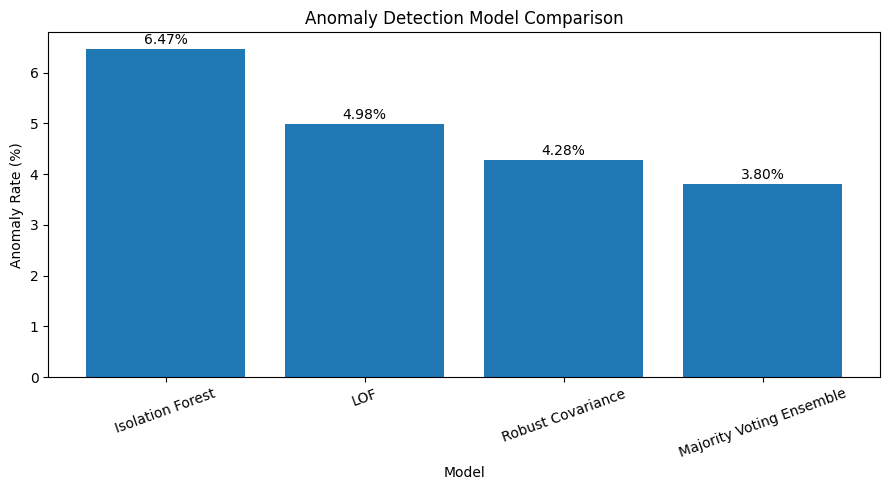

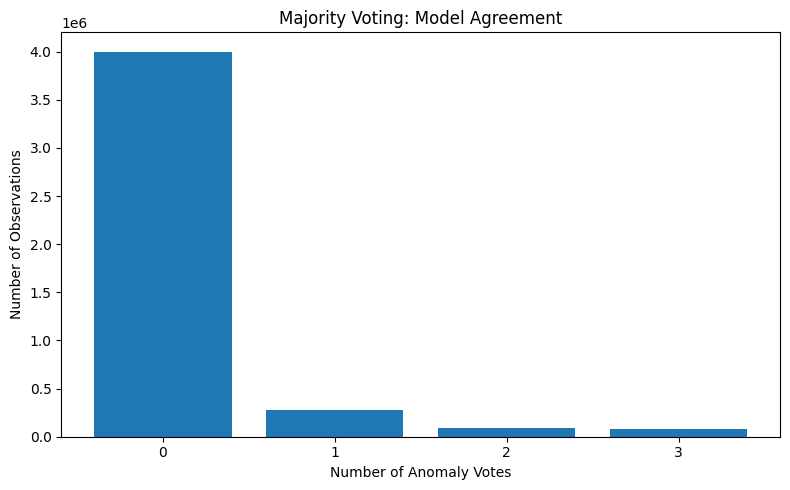

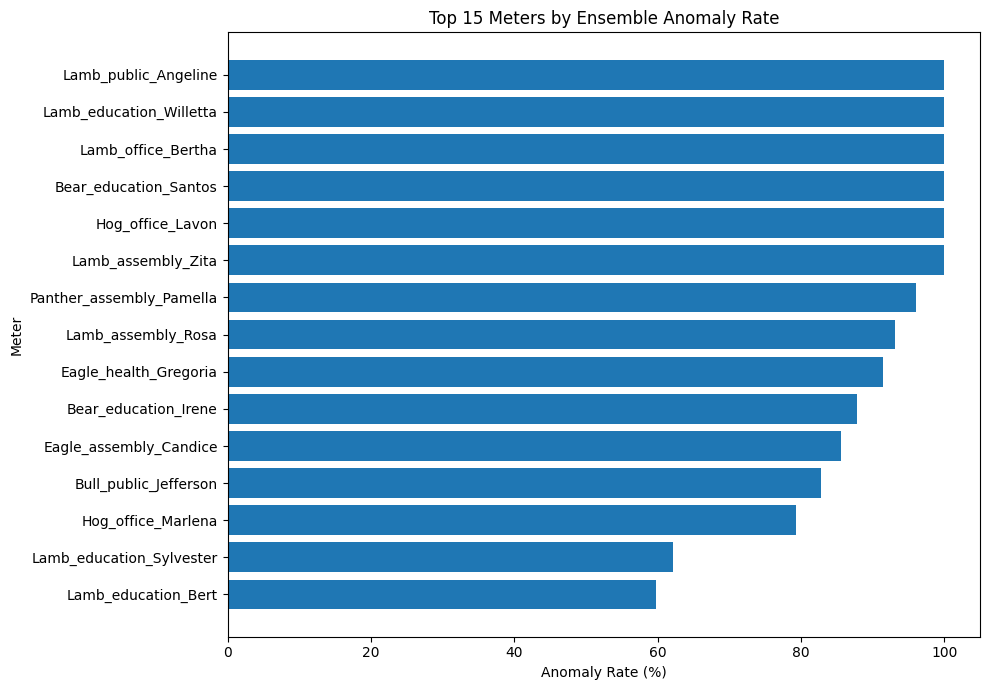

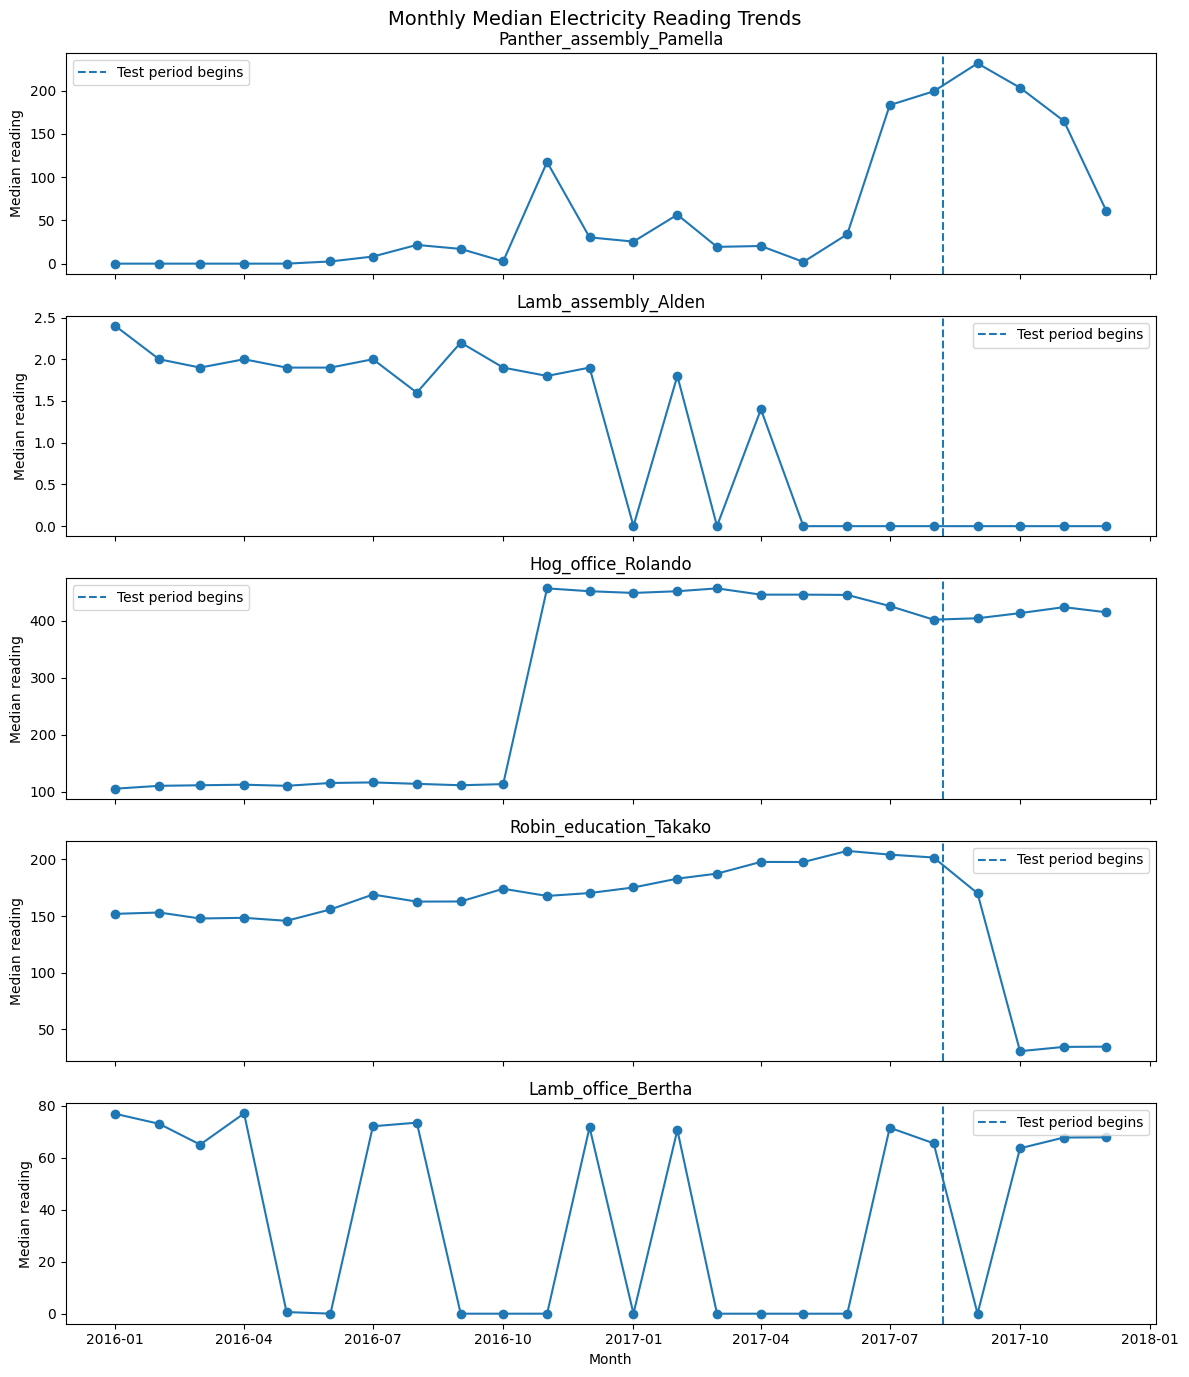

In [149]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# --------------------------------------------------
# CHART 1: Model comparison
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

plot_data = comparison_summary.set_index("Model")

ax.bar(
    plot_data.index,
    plot_data["Anomaly Rate (%)"]
)

ax.set_title("Anomaly Detection Model Comparison")
ax.set_ylabel("Anomaly Rate (%)")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=20)

for i, value in enumerate(plot_data["Anomaly Rate (%)"]):
    ax.text(i, value + 0.1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# CHART 2: Ensemble vote distribution
# --------------------------------------------------

vote_counts = (
    full_ensemble_results["anomaly_votes"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    vote_counts.index.astype(str),
    vote_counts.values
)

ax.set_title("Majority Voting: Model Agreement")
ax.set_xlabel("Number of Anomaly Votes")
ax.set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# CHART 3: Top 15 meters by ensemble anomaly rate
# --------------------------------------------------

top15 = full_meter_summary.head(15).sort_values(
    "anomaly_rate"
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top15["meter"],
    top15["anomaly_rate"]
)

ax.set_title("Top 15 Meters by Ensemble Anomaly Rate")
ax.set_xlabel("Anomaly Rate (%)")
ax.set_ylabel("Meter")

plt.tight_layout()
plt.show()


# --------------------------------------------------
# CHART 4: Monthly median reading trends
# --------------------------------------------------

selected_meters = [
    "Panther_assembly_Pamella",
    "Lamb_assembly_Alden",
    "Hog_office_Rolando",
    "Robin_education_Takako",
    "Lamb_office_Bertha"
]

fig, axes = plt.subplots(
    len(selected_meters), 1,
    figsize=(12, 14),
    sharex=True
)

for ax, meter in zip(axes, selected_meters):

    monthly_median = (
        model_data.loc[:, meter]
        .resample("MS")
        .median()
    )

    ax.plot(
        monthly_median.index,
        monthly_median.values,
        marker="o"
    )

    ax.axvline(
        pd.Timestamp(test_start),
        linestyle="--",
        label="Test period begins"
    )

    ax.set_title(meter)
    ax.set_ylabel("Median reading")
    ax.legend()

axes[-1].set_xlabel("Month")

fig.suptitle(
    "Monthly Median Electricity Reading Trends",
    fontsize=14
)

plt.tight_layout()
plt.show()